<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%2012/DS_Practice_FullPipeline_Advanced.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%20X/DS_Practice_FullPipeline_Advanced.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Data Science
## Practice Session: The Full Machine Learning Pipeline, End to End
**Eötvös Loránd University (ELTE) · Faculty of Informatics**

---
**Instructor:** Arafat Md Easin  
**Goal:** By the end of this session you will be able to:
- Run a **complete project** from raw data to a deployable model: audit, clean, engineer, scale, select, model, tune, evaluate
- Build **leak-proof pipelines** with `ColumnTransformer`, custom transformers, and `Pipeline`
- Compare **CART, Random Forest, boosting, Voting, and Stacking** with repeated cross-validation and significance tests
- Apply the **full evaluation toolbox**: CV, nested CV, bootstrap CIs, ROC/PR, calibration, thresholds, learning curves, McNemar
- Interpret and **audit** a model (permutation importance, partial dependence, subgroup errors) and **save it for deployment**

> **Tip:** Run each cell with `Shift + Enter` and read the comments carefully before moving on.  
> **Key principle:** Every decision in a pipeline (imputer, scaler, features, model, threshold) must be learned on training data only and judged on data the model has never seen. The test set is opened exactly once.

---

## The Project and the Pipeline Map

**Goal:** predict whether a Titanic passenger **survived** (`1`) or not (`0`) from the information available at boarding.

The data is small, but it is deliberately messy in the ways real data is: **missing values**, **skewed numbers with outliers**, **categorical columns**, **leaky and redundant columns**, and **informative missingness**.

| Stage | Question it answers | Part |
|---|---|---|
| **1. Audit** | What do we have? What is broken, missing, redundant, or leaking the answer? | 1 |
| **2. EDA** | Which patterns and relationships exist? | 2 |
| **3. Split** | How do we guarantee an honest final test? | 3 |
| **4. Preprocess** | How do we impute, treat outliers, encode, and scale correctly? | 4 |
| **5. Engineer** | Can we create features the model cannot discover alone? | 5 |
| **6. Select** | Which features are worth keeping? | 6 |
| **7. Model** | Which algorithms fit? How does CART work? | 7 |
| **8. Ensemble** | Does combining models help? Bagging, boosting, voting, stacking | 8 |
| **9. Tune** | Which hyperparameters? How do we avoid fooling ourselves? | 9 |
| **10. Evaluate** | How good is the final model, how sure are we, where does it fail? | 10 |
| **11. Deploy** | How do we save it and use it on a new passenger? | 11 |

> **Golden rule:** **every** step that learns something from data (imputer medians, scaler means, encoder categories, selected features, model weights) lives **inside** a `Pipeline` and is fitted on training folds only.

---
## Part 0: Setup & Data Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings, time, joblib
from functools import partial
warnings.filterwarnings('ignore')

from scipy import stats
from scipy.stats import randint, loguniform

from sklearn.experimental import enable_iterative_imputer          # noqa: needed for IterativeImputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder,
                                   PowerTransformer, QuantileTransformer, FunctionTransformer)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_score, cross_val_predict,
                                     GridSearchCV, RandomizedSearchCV, learning_curve, validation_curve)
from sklearn.feature_selection import SelectKBest, mutual_info_classif, f_classif, RFE, SelectFromModel
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              BaggingClassifier, VotingClassifier, StackingClassifier)
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, cohen_kappa_score, roc_auc_score,
                             average_precision_score, log_loss, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_curve,
                             precision_recall_curve)

# ── Reproducibility ───────────────────────────────────────────────────
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ── Plot style ────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"]     = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Setup complete.")

Setup complete.


In [ ]:
# ── 0.1  Load the raw data ────────────────────────────────────────────
# The Titanic table ships with seaborn (it is downloaded from GitHub on first use, so Colab needs internet).
# Target: survived (1 = survived, 0 = died).

df_raw = sns.load_dataset("titanic")

print(f"Rows: {df_raw.shape[0]},  Columns: {df_raw.shape[1]}")
df_raw.head(8)

Rows: 891,  Columns: 15


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False


---
## Part 1: Data Audit

Before any modelling, **interrogate the data**. An audit answers four questions:

| Question | Tool |
|---|---|
| **What types and ranges do we have?** | `dtypes`, `describe`, `nunique` |
| **What is missing, and how much?** | Missing-value counts and percentages |
| **Is the target balanced?** | Class counts |
| **Does any column leak the answer or duplicate another?** | Cross-tabulations and equality checks |

> **Data leakage** means a feature contains information that would not exist at prediction time (or is a copy of the target). A leaky model looks brilliant in validation and collapses in the real world.

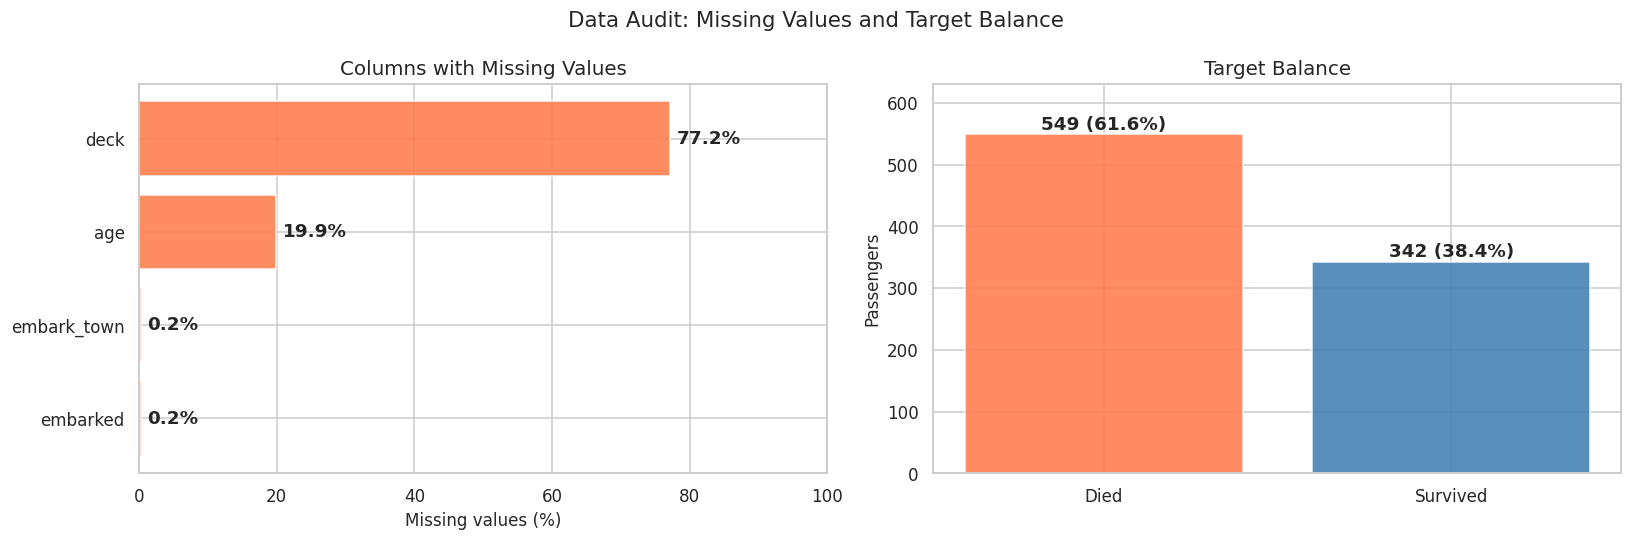

                dtype  n_missing  pct_missing  n_unique
survived        int64          0          0.0         2
pclass          int64          0          0.0         3
sex               str          0          0.0         2
age           float64        177         19.9        88
sibsp           int64          0          0.0         7
parch           int64          0          0.0         7
fare          float64          0          0.0       248
embarked          str          2          0.2         3
class        category          0          0.0         3
who               str          0          0.0         3
adult_male       bool          0          0.0         2
deck         category        688         77.2         7
embark_town       str          2          0.2         3
alive             str          0          0.0         2
alone            bool          0          0.0         2

Fully duplicated rows: 107  (no passenger ID or name here, so identical rows are plausible, not errors)

In [ ]:
# ── 1.1  Types, missing values, cardinality, target balance ───────────

audit = pd.DataFrame({
    "dtype":       df_raw.dtypes.astype(str),
    "n_missing":   df_raw.isna().sum(),
    "pct_missing": (df_raw.isna().mean() * 100).round(1),
    "n_unique":    df_raw.nunique(),
})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Data Audit: Missing Values and Target Balance", fontsize=14)

miss = audit[audit["n_missing"] > 0].sort_values("pct_missing")
axes[0].barh(miss.index, miss["pct_missing"], color="coral", edgecolor="white", alpha=0.9)
for i, v in enumerate(miss["pct_missing"]):
    axes[0].text(v + 1, i, f"{v}%", va="center", fontweight="bold")
axes[0].set_xlim(0, 100)
axes[0].set_xlabel("Missing values (%)")
axes[0].set_title("Columns with Missing Values")

counts = df_raw["survived"].map({0: "Died", 1: "Survived"}).value_counts()[["Died", "Survived"]]
axes[1].bar(counts.index, counts.values, color=["coral", "steelblue"], edgecolor="white", alpha=0.9)
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 8, f"{v} ({v / len(df_raw) * 100:.1f}%)", ha="center", fontweight="bold")
axes[1].set_ylim(0, counts.max() * 1.15)
axes[1].set_title("Target Balance")
axes[1].set_ylabel("Passengers")

plt.tight_layout()
plt.show()

print(audit.to_string())
print(f"\nFully duplicated rows: {df_raw.duplicated().sum()}  (no passenger ID or name here, so identical rows are plausible, not errors)")
print("Moderate imbalance (about 38% survived): stratified splits are needed; accuracy alone is not enough.")

In [ ]:
# ── 1.2  Leakage and redundancy checks ───────────────────────────────
# Several columns are copies or simple functions of others. We PROVE it rather than assume it.

checks = {
    "alive == survived (text copy of the TARGET)":
        (df_raw["alive"].map({"yes": 1, "no": 0}) == df_raw["survived"]).mean(),
    "class == pclass (same information, as text)":
        (df_raw["class"].astype(str) == df_raw["pclass"].map({1: "First", 2: "Second", 3: "Third"})).mean(),
    "embark_town == embarked (full name vs letter)":
        (df_raw["embark_town"].fillna("?") == df_raw["embarked"].map(
            {"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"}).fillna("?")).mean(),
    "alone == (sibsp + parch == 0)":
        (df_raw["alone"] == ((df_raw["sibsp"] + df_raw["parch"]) == 0)).mean(),
    "adult_male == (sex is male and age >= 16)":
        (df_raw["adult_male"] == ((df_raw["sex"] == "male") & (df_raw["age"] >= 16))).mean(),
}
for name, frac in checks.items():
    print(f"{frac * 100:6.1f}% identical   {name}")

print("\nadult_male and who (man / woman / child) are built from sex and age, but adult_male matches our rule only 86% of the time:")
print("they use an undocumented rule for the missing ages. That hidden imputation is another reason to drop them and do it ourselves.")

LEAKY_OR_REDUNDANT = ["alive", "class", "embark_town", "who", "adult_male", "alone"]
print(f"\nDropping: {LEAKY_OR_REDUNDANT}")
print("'alive' leaks the target. The rest add no information beyond other columns, and 'alone' / 'adult_male' / 'who'")
print("hide the missing ages inside engineered values. We will rebuild useful versions ourselves inside the pipeline.")

 100.0% identical   alive == survived (text copy of the TARGET)
 100.0% identical   class == pclass (same information, as text)
 100.0% identical   embark_town == embarked (full name vs letter)
 100.0% identical   alone == (sibsp + parch == 0)
  86.1% identical   adult_male == (sex is male and age >= 16)

adult_male and who (man / woman / child) are built from sex and age, but adult_male matches our rule only 86% of the time:
they use an undocumented rule for the missing ages. That hidden imputation is another reason to drop them and do it ourselves.

Dropping: ['alive', 'class', 'embark_town', 'who', 'adult_male', 'alone']
'alive' leaks the target. The rest add no information beyond other columns, and 'alone' / 'adult_male' / 'who'
hide the missing ages inside engineered values. We will rebuild useful versions ourselves inside the pipeline.


---
## Part 2: Exploratory Data Analysis

EDA is for **understanding and generating hypotheses**, not for fitting anything. Note that here we look at the whole table for exploration only; every number that will be *learned* (medians, scalers, selectors) is computed later, on the training set alone.

> **Pair visuals with tests.** A bar chart suggests a relationship; a **chi-square** test (categorical vs target) or **Mann-Whitney U** test (numeric vs target) quantifies whether it is likely to be real, and an **effect size** says whether it is big enough to matter.

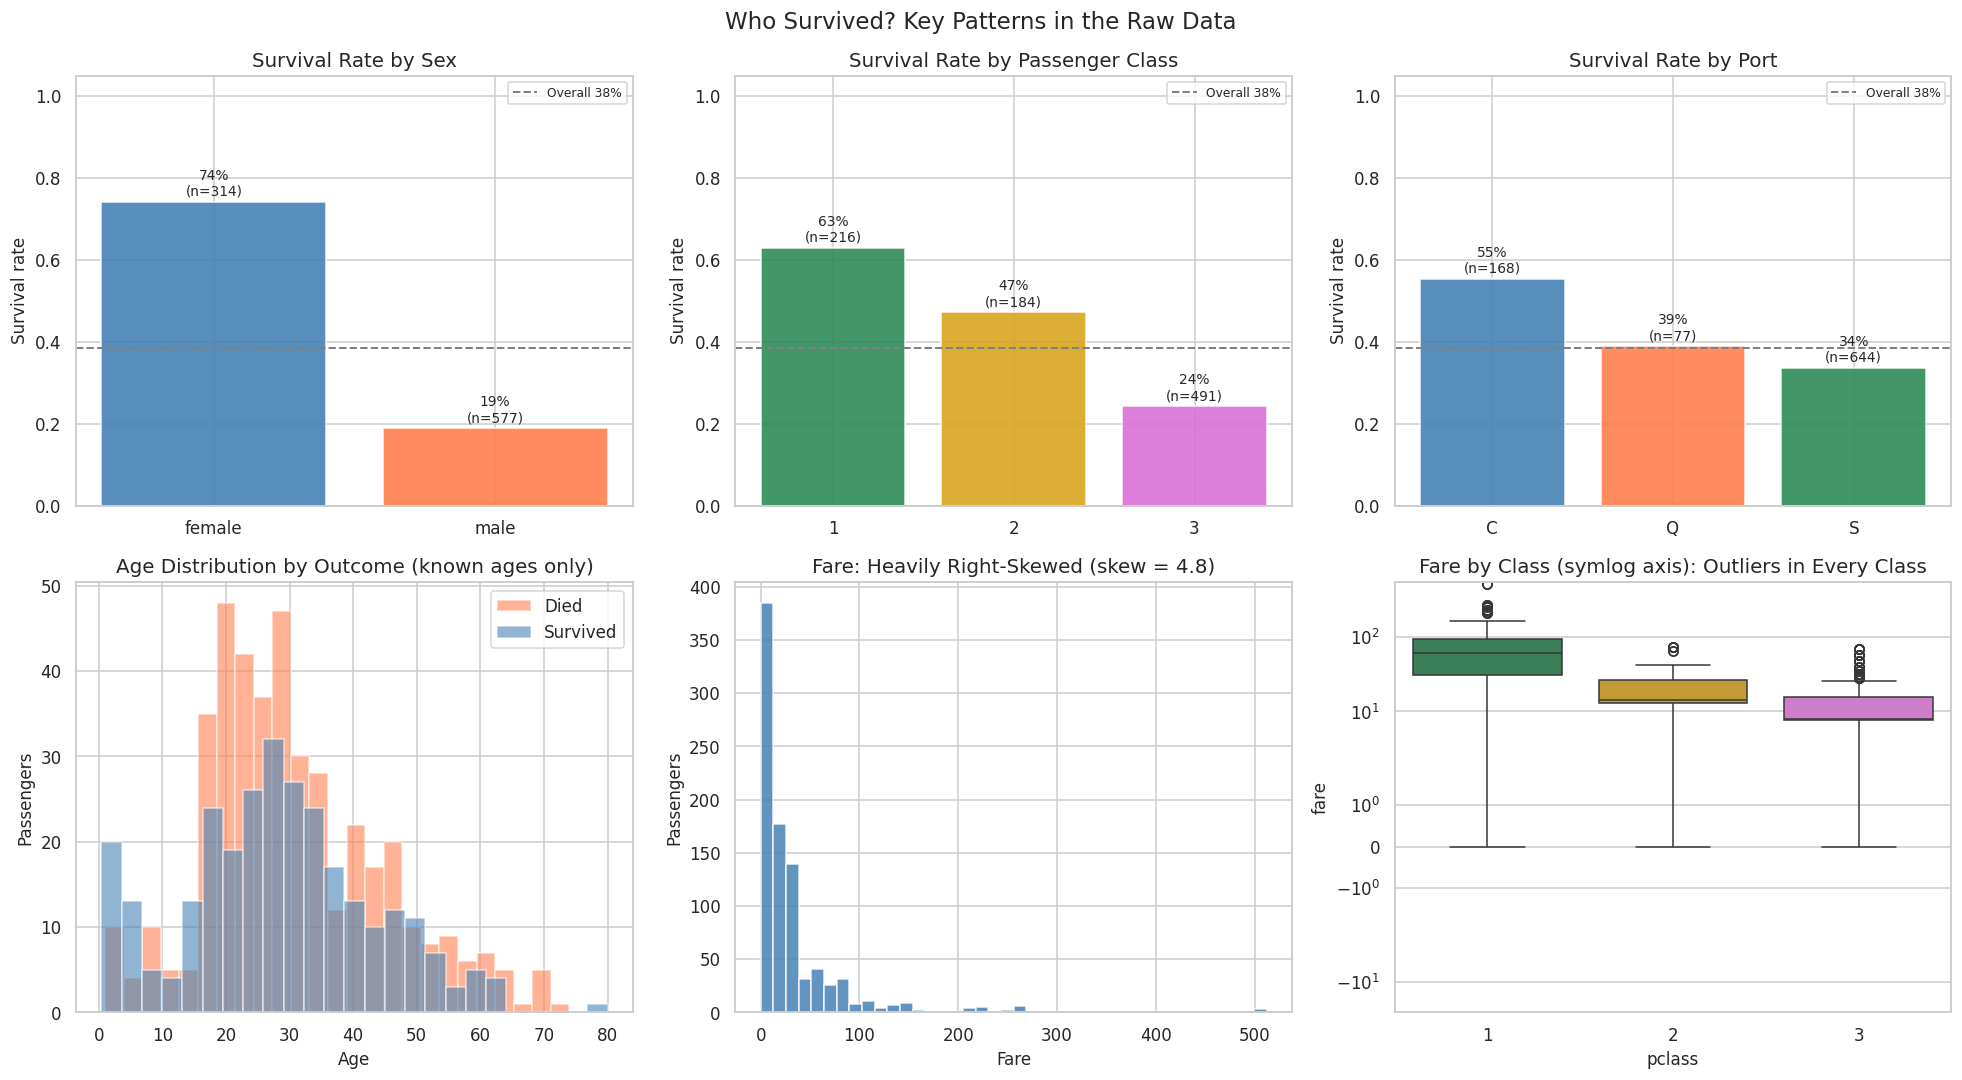

In [ ]:
# ── 2.1  Survival patterns ───────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Who Survived? Key Patterns in the Raw Data", fontsize=15)
overall = df_raw["survived"].mean()

def rate_bar(ax, col, title, colors):
    g = df_raw.groupby(col)["survived"].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"], color=colors, edgecolor="white", alpha=0.9)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.015, f"{m:.0%}\n(n={n})", ha="center", fontsize=9)
    ax.axhline(overall, color="grey", linestyle="--", linewidth=1.3, label=f"Overall {overall:.0%}")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Survival rate")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8)

rate_bar(axes[0, 0], "sex",      "Survival Rate by Sex",             ["steelblue", "coral"])
rate_bar(axes[0, 1], "pclass",   "Survival Rate by Passenger Class", ["seagreen", "goldenrod", "orchid"])
rate_bar(axes[0, 2], "embarked", "Survival Rate by Port",            ["steelblue", "coral", "seagreen"])

for label, color, name in [(0, "coral", "Died"), (1, "steelblue", "Survived")]:
    axes[1, 0].hist(df_raw.loc[df_raw["survived"] == label, "age"].dropna(), bins=25, alpha=0.6,
                    color=color, label=name, edgecolor="white")
axes[1, 0].set_xlabel("Age"); axes[1, 0].set_ylabel("Passengers"); axes[1, 0].legend()
axes[1, 0].set_title("Age Distribution by Outcome (known ages only)")

axes[1, 1].hist(df_raw["fare"], bins=40, color="steelblue", edgecolor="white", alpha=0.85)
axes[1, 1].set_xlabel("Fare"); axes[1, 1].set_ylabel("Passengers")
axes[1, 1].set_title(f"Fare: Heavily Right-Skewed (skew = {stats.skew(df_raw['fare']):.1f})")

sns.boxplot(data=df_raw, x="pclass", y="fare", palette=["seagreen", "goldenrod", "orchid"], ax=axes[1, 2])
axes[1, 2].set_yscale("symlog")
axes[1, 2].set_title("Fare by Class (symlog axis): Outliers in Every Class")

plt.tight_layout()
plt.show()

                    test   statistic   p_value  effect_size      effect_name
feature                                                                     
sex           chi-square     260.717  1.20e-58        0.541       Cramer's V
pclass        chi-square     102.889  4.55e-23        0.340       Cramer's V
embarked      chi-square      26.489  1.77e-06        0.173       Cramer's V
age       Mann-Whitney U   57682.000  1.60e-01        0.062  rank-biserial r
fare      Mann-Whitney U  129951.500  4.55e-22        0.384  rank-biserial r
sibsp     Mann-Whitney U  101983.000  8.02e-03        0.086  rank-biserial r
parch     Mann-Whitney U  105373.000  3.71e-05        0.122  rank-biserial r


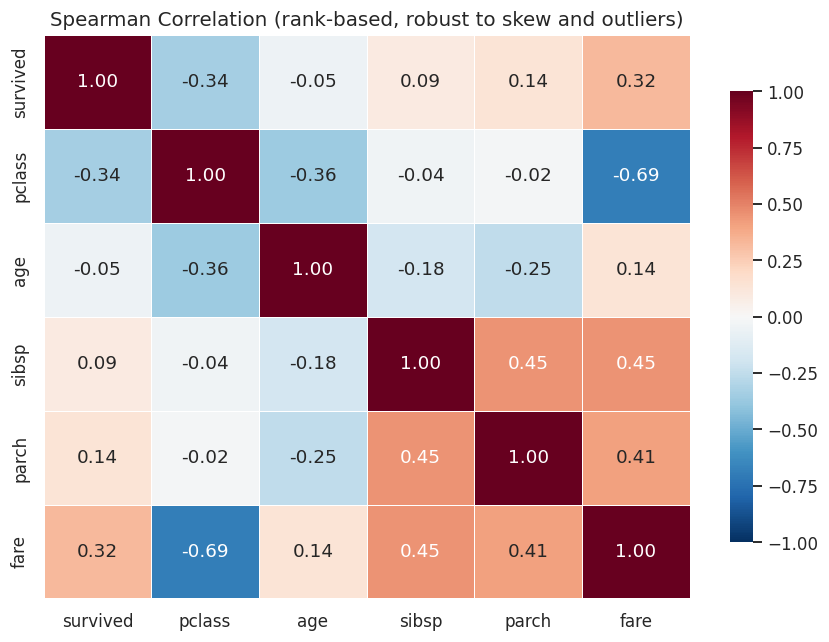

Sex is by far the strongest signal, then fare and class (fare is partly a proxy for class: note the pclass-fare correlation).
p-values only say 'unlikely to be chance'. The effect size says how much it matters.


In [ ]:
# ── 2.2  Are the patterns statistically real? ────────────────────────

rows = []
for col in ["sex", "pclass", "embarked"]:
    ct = pd.crosstab(df_raw[col], df_raw["survived"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({"feature": col, "test": "chi-square", "statistic": chi2, "p_value": p, "effect_size": cramers_v,
                 "effect_name": "Cramer's V"})
for col in ["age", "fare", "sibsp", "parch"]:
    a = df_raw.loc[df_raw["survived"] == 1, col].dropna()
    b = df_raw.loc[df_raw["survived"] == 0, col].dropna()
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"feature": col, "test": "Mann-Whitney U", "statistic": u, "p_value": p,
                 "effect_size": abs(2 * u / (len(a) * len(b)) - 1), "effect_name": "rank-biserial r"})
tests = pd.DataFrame(rows).set_index("feature")
tests["p_value"] = tests["p_value"].map(lambda v: f"{v:.2e}")
print(tests.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
num = df_raw[["survived", "pclass", "age", "sibsp", "parch", "fare"]]
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Spearman Correlation (rank-based, robust to skew and outliers)")
plt.tight_layout()
plt.show()

print("Sex is by far the strongest signal, then fare and class (fare is partly a proxy for class: note the pclass-fare correlation).")
print("p-values only say 'unlikely to be chance'. The effect size says how much it matters.")

---
## Part 3: The Sealed Test Set and the Validation Strategy

Two decisions made **before any learning**:

1. **Hold out a test set** (20%), stratified on the target, and do not touch it until Part 10. Everything we fit later learns from the **training set only**.
2. **Choose a cross-validation scheme** for model comparison *inside* the training set.

| Scheme | What it does | Use when |
|---|---|---|
| **Hold-out** | One split | Large data; the final test |
| **Stratified K-Fold** | K folds keeping class ratios | Default for classification |
| **Repeated Stratified K-Fold** | K-fold repeated with different shuffles | Small data: reduces the luck of one split |
| **Nested CV** | Tune in an inner loop, score in an outer loop | Honest estimate **including** the tuning (Part 9) |
| **Bootstrap** | Resample with replacement | Confidence intervals (Part 10) |

In [ ]:
# ── 3.1  Drop leaky columns, split, define the CV schemes ────────────

df = df_raw.drop(columns=LEAKY_OR_REDUNDANT).copy()
df["deck"] = df["deck"].astype(object)           # pandas category -> plain object so NaN handling is uniform

X = df.drop(columns="survived")
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

cv      = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)   # main comparisons (10 folds)
cv_fast = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)          # cheaper steps

print(f"Features: {list(X.columns)}")
print(f"Train: {X_train.shape[0]} rows ({y_train.mean():.1%} survived)   Test: {X_test.shape[0]} rows ({y_test.mean():.1%} survived)")
print("\nThe test set is now sealed. From here on, every fit uses X_train / y_train only.")
X_train.head()

Features: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'deck']
Train: 712 rows (38.3% survived)   Test: 179 rows (38.5% survived)

The test set is now sealed. From here on, every fit uses X_train / y_train only.


,pclass,sex,age,sibsp,parch,fare,embarked,deck
692,3,male,NaN,0,0,56.4958,S,NaN
481,2,male,NaN,0,0,0.0000,S,NaN
527,1,male,NaN,0,0,221.7792,S,C
855,3,female,18.0,0,1,9.3500,S,NaN
801,2,female,31.0,1,1,26.2500,S,NaN


---
## Part 4: Preprocessing

Raw columns cannot go straight into most models. Four problems need solving, each with a **fit on training data, apply to everything** step:

| Problem | Options | Notes |
|---|---|---|
| **Missing values** | Mean / median / most frequent, KNN, iterative (regression), **missing-indicator flags** | Missingness can itself be informative |
| **Outliers and skew** | Keep, clip (winsorise), `log1p`, Yeo-Johnson, quantile transform, robust scaling | Do not delete real extreme values (a 500-pound fare is real) |
| **Categorical encoding** | One-hot (nominal), ordinal (ordered), target encoding (high cardinality) | Always `handle_unknown="ignore"` for unseen categories |
| **Scaling** | Standard, Min-Max, Robust | Needed by distance and gradient models; trees are invariant |

We explore each choice on the **training set**, then assemble the winners into one `ColumnTransformer`.

### 4.1 Missing Values

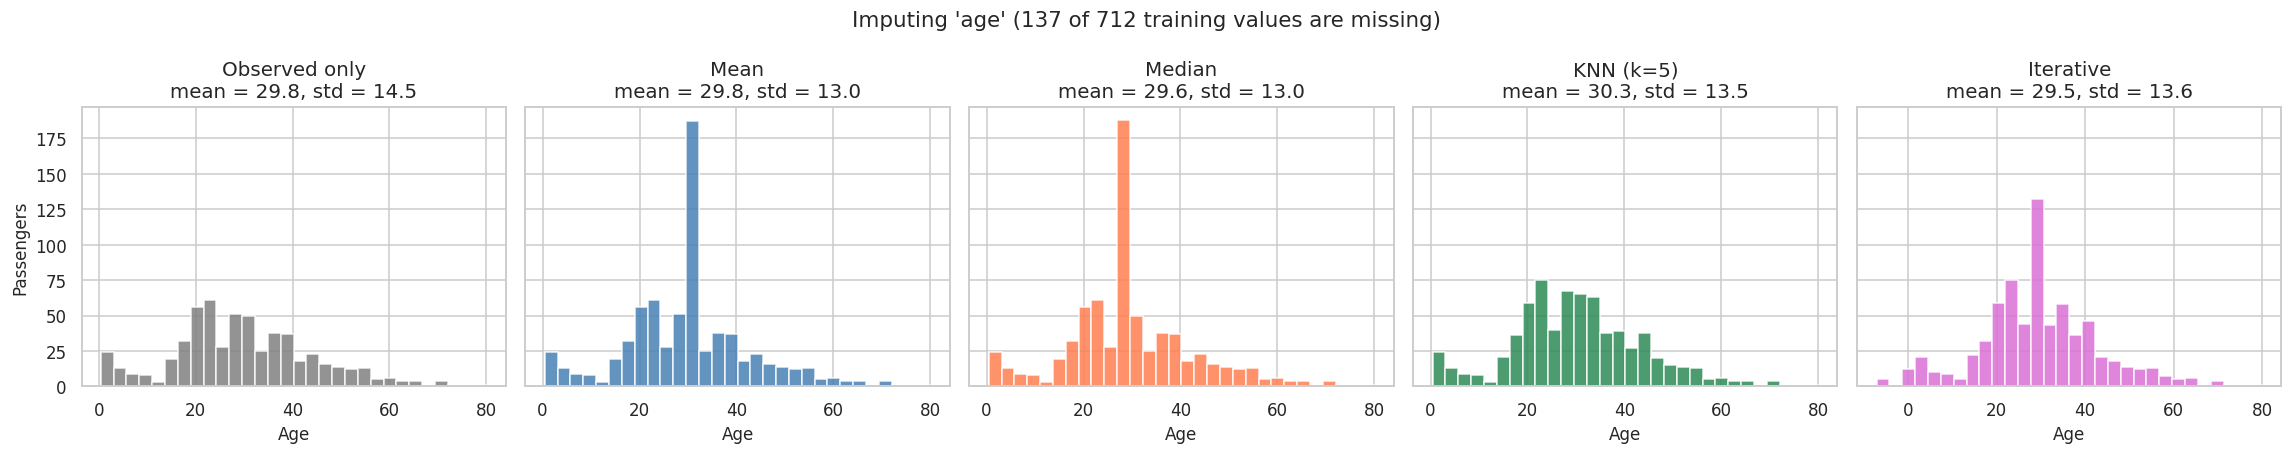

Mean and median imputation create a spike at one value and shrink the variance.
KNN and Iterative imputation preserve more of the spread by using the other columns.


In [ ]:
# ── 4.1a  Four imputers compared on the 'age' column ─────────────────
# KNN and Iterative imputers use the OTHER numeric columns to predict the missing age.

num_ref = ["age", "pclass", "sibsp", "parch", "fare"]
age_variants = {"Observed only": X_train["age"].dropna().values}
imputers = {"Mean":       SimpleImputer(strategy="mean"),
            "Median":     SimpleImputer(strategy="median"),
            "KNN (k=5)":  KNNImputer(n_neighbors=5),
            "Iterative":  IterativeImputer(random_state=RANDOM_STATE)}
for name, imp in imputers.items():
    age_variants[name] = imp.fit_transform(X_train[num_ref])[:, 0]

fig, axes = plt.subplots(1, 5, figsize=(21, 4.2), sharey=True)
fig.suptitle(f"Imputing 'age' ({X_train['age'].isna().sum()} of {len(X_train)} training values are missing)", fontsize=14)
for ax, (name, vals), color in zip(axes, age_variants.items(),
                                   ["grey", "steelblue", "coral", "seagreen", "orchid"]):
    ax.hist(vals, bins=30, color=color, edgecolor="white", alpha=0.85)
    ax.set_title(f"{name}\nmean = {vals.mean():.1f}, std = {vals.std():.1f}")
    ax.set_xlabel("Age")
axes[0].set_ylabel("Passengers")
plt.tight_layout()
plt.show()

print("Mean and median imputation create a spike at one value and shrink the variance.")
print("KNN and Iterative imputation preserve more of the spread by using the other columns.")

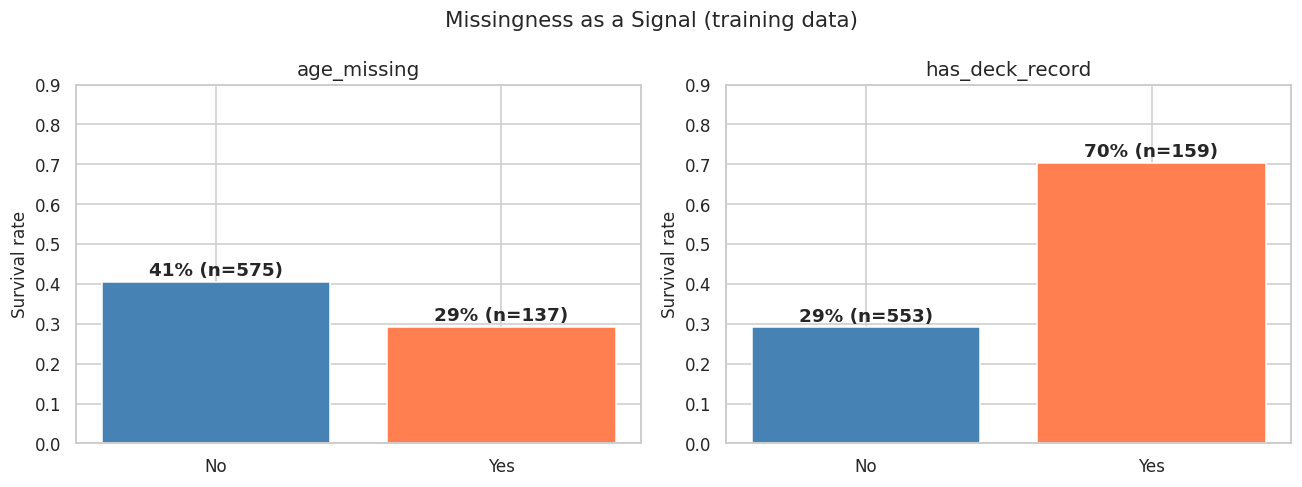

A cabin record exists mostly for upper-class passengers, so 'has a deck' is a strong class/wealth proxy.
Imputing the deck would destroy that signal. Instead we keep a missing-indicator feature (Part 5).


In [ ]:
# ── 4.1b  Is missingness itself informative? ─────────────────────────

flags = pd.DataFrame({"age_missing": X_train["age"].isna(), "has_deck_record": X_train["deck"].notna(),
                      "survived": y_train})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fig.suptitle("Missingness as a Signal (training data)", fontsize=14)
for ax, col in zip(axes, ["age_missing", "has_deck_record"]):
    g = flags.groupby(col)["survived"].agg(["mean", "size"])
    ax.bar(["No" if not i else "Yes" for i in g.index], g["mean"], color=["steelblue", "coral"], edgecolor="white")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.015, f"{m:.0%} (n={n})", ha="center", fontweight="bold")
    ax.set_ylim(0, 0.9); ax.set_ylabel("Survival rate"); ax.set_title(col)
plt.tight_layout()
plt.show()

print("A cabin record exists mostly for upper-class passengers, so 'has a deck' is a strong class/wealth proxy.")
print("Imputing the deck would destroy that signal. Instead we keep a missing-indicator feature (Part 5).")

In [ ]:
# ── 4.1c  Does the imputer choice change model performance? ───────────
# A small, fair test: same Logistic Regression, only the imputer changes. Imputation lives INSIDE the pipeline,
# so each CV fold learns its medians / neighbours from its own training part only.

def quick_prep(scaler=None, imputer=None):
    scaler  = StandardScaler() if scaler is None else scaler
    imputer = SimpleImputer(strategy="median") if imputer is None else imputer
    sc = scaler if isinstance(scaler, str) else clone(scaler)
    return ColumnTransformer([
        ("num", Pipeline([("imp", clone(imputer)), ("sc", sc)]), ["age", "sibsp", "parch", "fare", "pclass"]),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]), ["sex", "embarked"]),
    ])

rows = []
for name, imp in imputers.items():
    pipe = Pipeline([("prep", quick_prep(imputer=imp)), ("clf", LogisticRegression(max_iter=2000))])
    r = cross_validate(pipe, X_train, y_train, cv=cv_fast, scoring={"acc": "accuracy", "auc": "roc_auc"})
    rows.append({"imputer": name, "cv_accuracy": r["test_acc"].mean(), "cv_roc_auc": r["test_auc"].mean()})
imp_df = pd.DataFrame(rows).set_index("imputer")
print(imp_df.round(4).to_string())
print("\nThe differences are typically small. What matters far more is fitting the imputer inside the pipeline.")

           cv_accuracy  cv_roc_auc
imputer                           
Mean            0.7963      0.8556
Median          0.7963      0.8551
KNN (k=5)       0.8020      0.8551
Iterative       0.8034      0.8547

The differences are typically small. What matters far more is fitting the imputer inside the pipeline.


### 4.2 Outliers and Skew

Fare IQR fence: [-26.8, 65.7]   Outliers: 91 of 712 (12.8%)
These are real first-class tickets, not errors, so we TRANSFORM rather than delete.



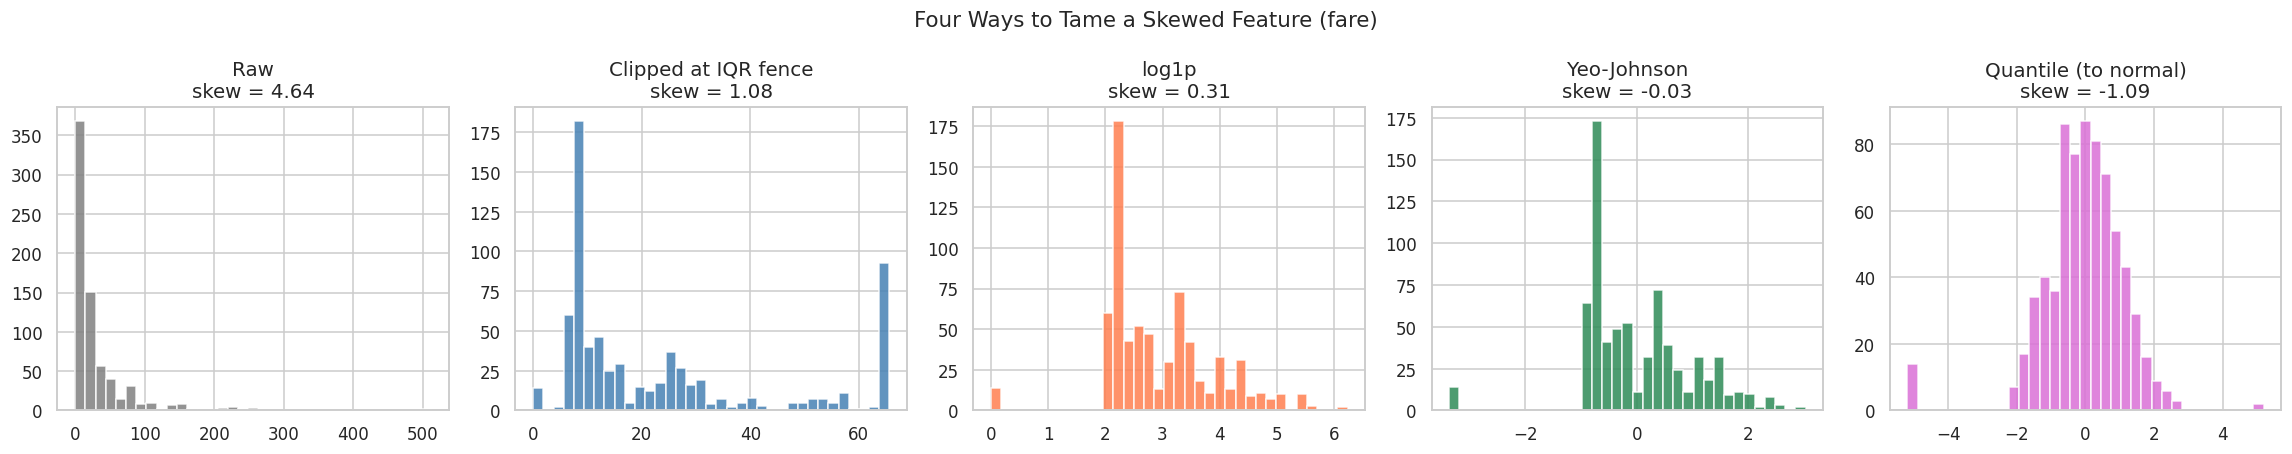

log1p is simple, stateless (no fitted parameters to leak), and handles the zero fares. We use it for fare-like columns.


In [ ]:
# ── 4.2  Treating the skewed 'fare' column ───────────────────────────
# IQR rule: a value is an outlier if it lies beyond Q1 - 1.5*IQR or Q3 + 1.5*IQR.

fare = X_train["fare"]
q1, q3 = fare.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = int(((fare < lo) | (fare > hi)).sum())
print(f"Fare IQR fence: [{lo:.1f}, {hi:.1f}]   Outliers: {n_out} of {len(fare)} ({n_out / len(fare) * 100:.1f}%)")
print("These are real first-class tickets, not errors, so we TRANSFORM rather than delete.\n")

col = fare.values.reshape(-1, 1)
variants = {
    "Raw":                         col.ravel(),
    "Clipped at IQR fence":        fare.clip(lo, hi).values,
    "log1p":                       np.log1p(col).ravel(),
    "Yeo-Johnson":                 PowerTransformer().fit_transform(col).ravel(),
    "Quantile (to normal)":        QuantileTransformer(output_distribution="normal", n_quantiles=200,
                                                       random_state=RANDOM_STATE).fit_transform(col).ravel(),
}

fig, axes = plt.subplots(1, 5, figsize=(21, 4.2))
fig.suptitle("Four Ways to Tame a Skewed Feature (fare)", fontsize=14)
for ax, (name, vals), color in zip(axes, variants.items(), ["grey", "steelblue", "coral", "seagreen", "orchid"]):
    ax.hist(vals, bins=35, color=color, edgecolor="white", alpha=0.85)
    ax.set_title(f"{name}\nskew = {stats.skew(vals):.2f}")
plt.tight_layout()
plt.show()

print("log1p is simple, stateless (no fitted parameters to leak), and handles the zero fares. We use it for fare-like columns.")

### 4.3 Categorical Encoding

| Column type | Example | Encoding |
|---|---|---|
| **Nominal** (no order) | `sex`, `embarked` | **One-hot**: one 0/1 column per category |
| **Ordinal** (ordered) | `pclass` 1 < 2 < 3 | Keep as a number, or `OrdinalEncoder` |
| **High cardinality** | ZIP code, product ID | Target encoding (`sklearn.preprocessing.TargetEncoder`, fitted inside CV) or hashing |

> **Unseen categories:** at prediction time a category may appear that was never in the training data. `OneHotEncoder(handle_unknown="ignore")` encodes it as all zeros instead of crashing.

In [ ]:
# ── 4.3  One-hot encoding in practice, including an unseen category ──

cat_df = X_train[["sex", "embarked"]].fillna("missing")
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(cat_df)
encoded = pd.DataFrame(ohe.transform(cat_df), columns=ohe.get_feature_names_out(), index=cat_df.index)

print("Learned categories:", {c: list(v) for c, v in zip(cat_df.columns, ohe.categories_)})
print("\nFirst rows, original vs encoded:")
print(pd.concat([cat_df.head(5), encoded.head(5)], axis=1).to_string())

unseen = pd.DataFrame({"sex": ["female"], "embarked": ["Z"]})     # port 'Z' never occurred in training
print("\nUnseen port 'Z' encodes as:", dict(zip(ohe.get_feature_names_out(), ohe.transform(unseen)[0].astype(int))))
print("All embarked columns are 0 instead of an error. The model treats it as 'unknown port'.")

Learned categories: {'sex': ['female', 'male'], 'embarked': ['C', 'Q', 'S', 'missing']}

First rows, original vs encoded:
        sex embarked  sex_female  sex_male  embarked_C  embarked_Q  embarked_S  embarked_missing
692    male        S         0.0       1.0         0.0         0.0         1.0               0.0
481    male        S         0.0       1.0         0.0         0.0         1.0               0.0
527    male        S         0.0       1.0         0.0         0.0         1.0               0.0
855  female        S         1.0       0.0         0.0         0.0         1.0               0.0
801  female        S         1.0       0.0         0.0         0.0         1.0               0.0

Unseen port 'Z' encodes as: {'sex_female': np.int64(1), 'sex_male': np.int64(0), 'embarked_C': np.int64(0), 'embarked_Q': np.int64(0), 'embarked_S': np.int64(0), 'embarked_missing': np.int64(0)}
All embarked columns are 0 instead of an error. The model treats it as 'unknown port'.


### 4.4 Scaling: Which Models Care?

| Scaler | Formula | Best when |
|---|---|---|
| **StandardScaler** | $(x - \mu) / \sigma$ | Roughly Gaussian features |
| **MinMaxScaler** | $(x - x_{min}) / (x_{max} - x_{min})$ | Bounded range needed, no heavy outliers |
| **RobustScaler** | $(x - \text{median}) / \text{IQR}$ | Outliers present |

Distance-based and gradient-based models (KNN, SVM, Logistic Regression, neural nets) need scaling. **Tree-based models do not**: splits depend only on the **order** of values. We test this.

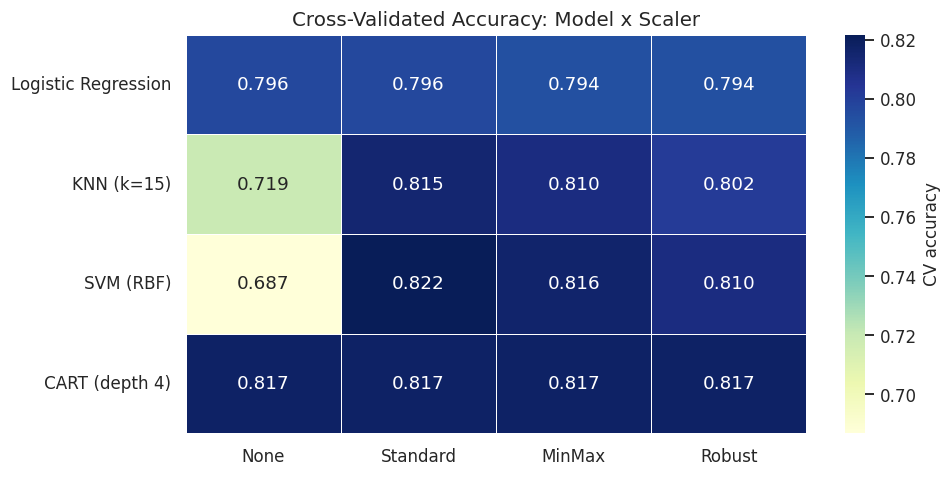

Accuracy spread across scalers (max - min):
Logistic Regression    0.0028
KNN (k=15)             0.0955
SVM (RBF)              0.1348
CART (depth 4)         0.0000

CART is unaffected by scaling; scale-sensitive models usually are. Scaling goes in the pipeline regardless.


In [ ]:
# ── 4.4  Model x scaler matrix ───────────────────────────────────────

scalers = {"None": "passthrough", "Standard": StandardScaler(), "MinMax": MinMaxScaler(), "Robust": RobustScaler()}
scale_models = {"Logistic Regression": LogisticRegression(max_iter=2000),
                "KNN (k=15)":          KNeighborsClassifier(15),
                "SVM (RBF)":           SVC(random_state=RANDOM_STATE),
                "CART (depth 4)":      DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)}

grid = pd.DataFrame(index=scale_models.keys(), columns=scalers.keys(), dtype=float)
for mname, model in scale_models.items():
    for sname, sc in scalers.items():
        pipe = Pipeline([("prep", quick_prep(scaler=sc)), ("clf", clone(model))])
        grid.loc[mname, sname] = cross_val_score(pipe, X_train, y_train, cv=cv_fast, scoring="accuracy").mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(grid, annot=True, fmt=".3f", cmap="YlGnBu", linewidths=0.5, ax=ax, cbar_kws={"label": "CV accuracy"})
ax.set_title("Cross-Validated Accuracy: Model x Scaler")
plt.tight_layout()
plt.show()

spread = (grid.max(axis=1) - grid.min(axis=1)).round(4)
print("Accuracy spread across scalers (max - min):")
print(spread.to_string())
print("\nCART is unaffected by scaling; scale-sensitive models usually are. Scaling goes in the pipeline regardless.")

### 4.5 Assembling the Preprocessor

A **`ColumnTransformer`** applies a different mini-pipeline to each group of columns and concatenates the results:

| Group | Columns | Steps |
|---|---|---|
| **Numeric** | `age`, `sibsp`, `parch`, `pclass` (+ engineered) | median impute, then scale |
| **Skewed** | `fare` (+ engineered) | median impute, `log1p`, then scale |
| **Categorical** | `sex`, `embarked` (+ engineered) | most-frequent impute, then one-hot |
| **Binary flags** | engineered 0/1 columns | pass through unchanged |

In [ ]:
# ── 4.5  The reusable preprocessor factory ───────────────────────────

def make_preprocessor(use_fe=True, scaler=None):
    scaler = StandardScaler() if scaler is None else scaler
    if use_fe:
        num, skew = ["age", "sibsp", "parch", "family_size", "pclass"], ["fare", "fare_per_person"]
        binary    = ["is_alone", "has_deck", "age_missing", "is_child"]
        cat       = ["sex", "embarked", "deck_group", "sex_pclass"]
    else:
        num, skew, binary, cat = ["age", "sibsp", "parch", "pclass"], ["fare"], [], ["sex", "embarked"]

    parts = [
        ("num",  Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", clone(scaler))]), num),
        ("skew", Pipeline([("imp", SimpleImputer(strategy="median")),
                           ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                           ("sc",  clone(scaler))]), skew),
        ("cat",  Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                           ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
    ]
    if binary:
        parts.append(("bin", "passthrough", binary))
    return ColumnTransformer(parts)

prep_basic = make_preprocessor(use_fe=False).fit(X_train)
Xt_basic   = prep_basic.transform(X_train)
names_basic = [n.split("__", 1)[1] for n in prep_basic.get_feature_names_out()]

print(f"Input:  {X_train.shape[1]} raw columns (mixed types, with NaN)")
print(f"Output: {Xt_basic.shape[1]} numeric columns, NaN left = {int(np.isnan(Xt_basic).sum())}")
print(f"Columns: {names_basic}")
pd.DataFrame(Xt_basic, columns=names_basic).describe().round(2).T[["mean", "std", "min", "max"]]

Input:  8 raw columns (mixed types, with NaN)
Output: 10 numeric columns, NaN left = 0
Columns: ['age', 'sibsp', 'parch', 'pclass', 'fare', 'sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S']


,mean,std,min,max
age,0.00,1.00,-2.24,3.88
sibsp,-0.00,1.00,-0.47,7.08
parch,-0.00,1.00,-0.47,6.70
pclass,-0.00,1.00,-1.57,0.83
fare,0.00,1.00,-3.01,3.36
sex_female,0.36,0.48,0.00,1.00
sex_male,0.64,0.48,0.00,1.00
embarked_C,0.20,0.40,0.00,1.00
embarked_Q,0.08,0.27,0.00,1.00
embarked_S,0.73,0.45,0.00,1.00


---
## Part 5: Feature Engineering

**Feature engineering** builds new columns that expose structure the model cannot easily find alone. Typical techniques:

| Technique | Example here |
|---|---|
| **Combine columns** | `family_size = sibsp + parch + 1` |
| **Ratios** | `fare_per_person = fare / family_size` |
| **Flags and missing indicators** | `has_deck`, `age_missing`, `is_alone`, `is_child` |
| **Binning / grouping** | `deck_group` (ABC, DE, FG, Unknown) |
| **Interactions** | `sex_pclass` (female in first class vs male in third) |
| *Other common ones* | date parts, text length, polynomial terms, aggregations per group |

> **Leak-proof engineering:** our transformer is **stateless** (it computes each row from that row only), so it learns nothing from the data and cannot leak. Features that need statistics (group means, target encoding) must be fitted inside the pipeline.

In [ ]:
# ── 5.1  A custom scikit-learn transformer ───────────────────────────

class TitanicFeatures(BaseEstimator, TransformerMixin):
    """Create new columns from the raw ones. Stateless: nothing is learned from the data."""

    NEW_COLS = ["family_size", "is_alone", "fare_per_person", "has_deck", "deck_group",
                "age_missing", "is_child", "sex_pclass"]

    def fit(self, X, y=None):
        self.feature_names_in_ = np.array(X.columns)
        return self

    def transform(self, X):
        X = X.copy()
        X["family_size"]     = X["sibsp"] + X["parch"] + 1
        X["is_alone"]        = (X["family_size"] == 1).astype(int)
        X["fare_per_person"] = X["fare"] / X["family_size"]
        X["has_deck"]        = X["deck"].notna().astype(int)
        X["deck_group"]      = X["deck"].map(lambda d: "ABC" if d in ("A", "B", "C") else
                                             "DE" if d in ("D", "E") else
                                             "FG" if d in ("F", "G") else "Unknown")
        X["age_missing"]     = X["age"].isna().astype(int)
        X["is_child"]        = (X["age"] < 12).astype(int)
        X["sex_pclass"]      = X["sex"].astype(str) + "_" + X["pclass"].astype(str)
        return X.drop(columns=["deck"])

    def get_feature_names_out(self, input_features=None):
        cols = self.feature_names_in_ if input_features is None else input_features
        return np.array([c for c in cols if c != "deck"] + self.NEW_COLS)

def make_pipeline(clf, use_fe=True, scaler=None):
    """Raw DataFrame in, predictions out: feature engineering -> preprocessing -> classifier."""
    steps = []
    if use_fe:
        steps.append(("fe", TitanicFeatures()))
    steps += [("prep", make_preprocessor(use_fe, scaler)), ("clf", clf)]
    return Pipeline(steps)

fe_demo = TitanicFeatures().fit_transform(X_train)
fe_demo["survived"] = y_train
print(f"Columns before: {X_train.shape[1]}   after feature engineering: {fe_demo.shape[1] - 1}")
fe_demo[TitanicFeatures.NEW_COLS + ["survived"]].head(6)

Columns before: 8   after feature engineering: 15


,family_size,is_alone,fare_per_person,has_deck,deck_group,age_missing,is_child,sex_pclass,survived
692,1,1,56.4958,0,Unknown,1,0,male_3,1
481,1,1,0.0000,0,Unknown,1,0,male_2,0
527,1,1,221.7792,1,ABC,1,0,male_1,0
855,2,0,4.6750,0,Unknown,0,0,female_3,1
801,3,0,8.7500,0,Unknown,0,0,female_2,1
652,1,1,8.4333,0,Unknown,0,0,male_3,0


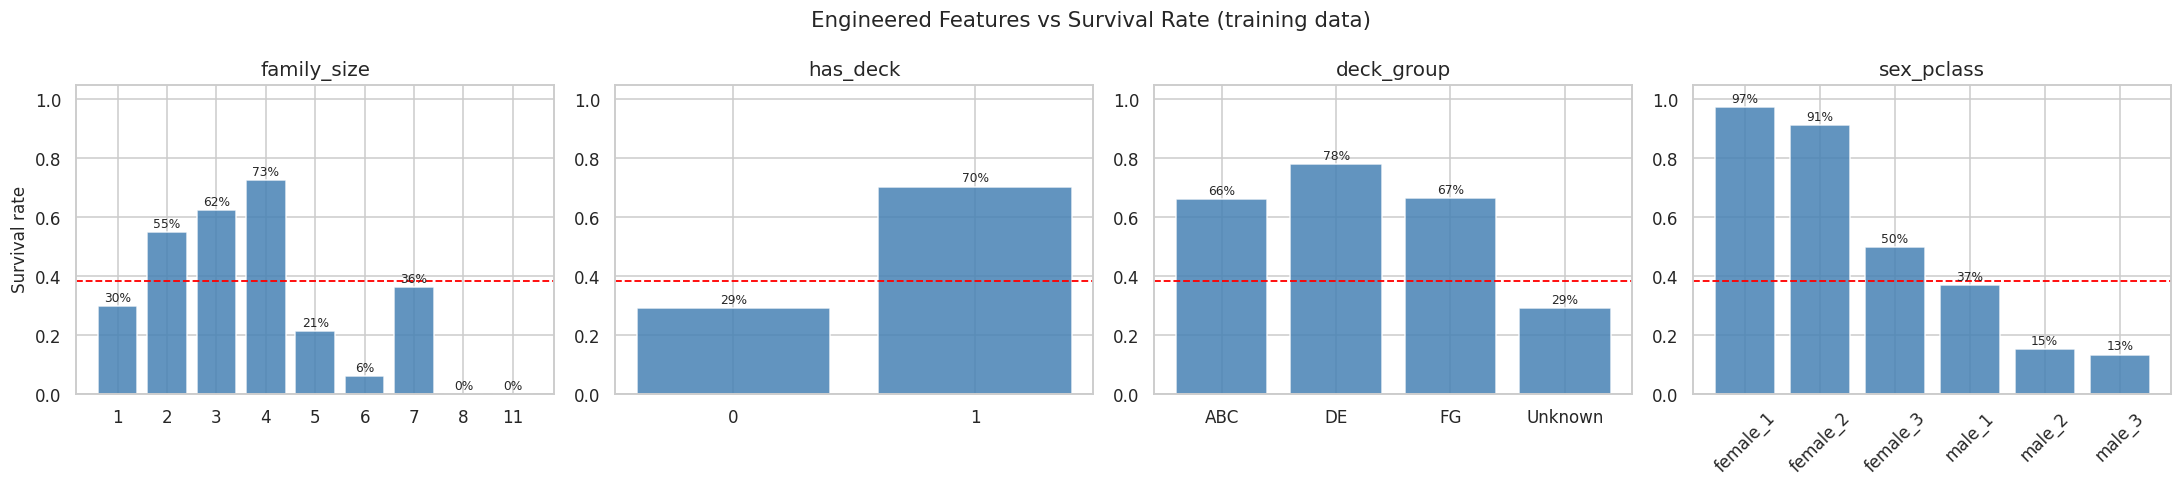

Small families survive more than singles and very large families. The relationship is non-monotonic,
so a single linear 'sibsp' coefficient cannot capture it. The sex x class interaction separates groups sharply.


In [ ]:
# ── 5.2  Do the new features carry signal? ───────────────────────────

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
fig.suptitle("Engineered Features vs Survival Rate (training data)", fontsize=14)
overall_tr = y_train.mean()

for ax, col in zip(axes, ["family_size", "has_deck", "deck_group", "sex_pclass"]):
    g = fe_demo.groupby(col)["survived"].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"], color="steelblue", edgecolor="white", alpha=0.85)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.015, f"{m:.0%}", ha="center", fontsize=8)
    ax.axhline(overall_tr, color="red", linestyle="--", linewidth=1.2)
    ax.set_ylim(0, 1.05)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45 if col == "sex_pclass" else 0)
axes[0].set_ylabel("Survival rate")
plt.tight_layout()
plt.show()

print("Small families survive more than singles and very large families. The relationship is non-monotonic,")
print("so a single linear 'sibsp' coefficient cannot capture it. The sex x class interaction separates groups sharply.")

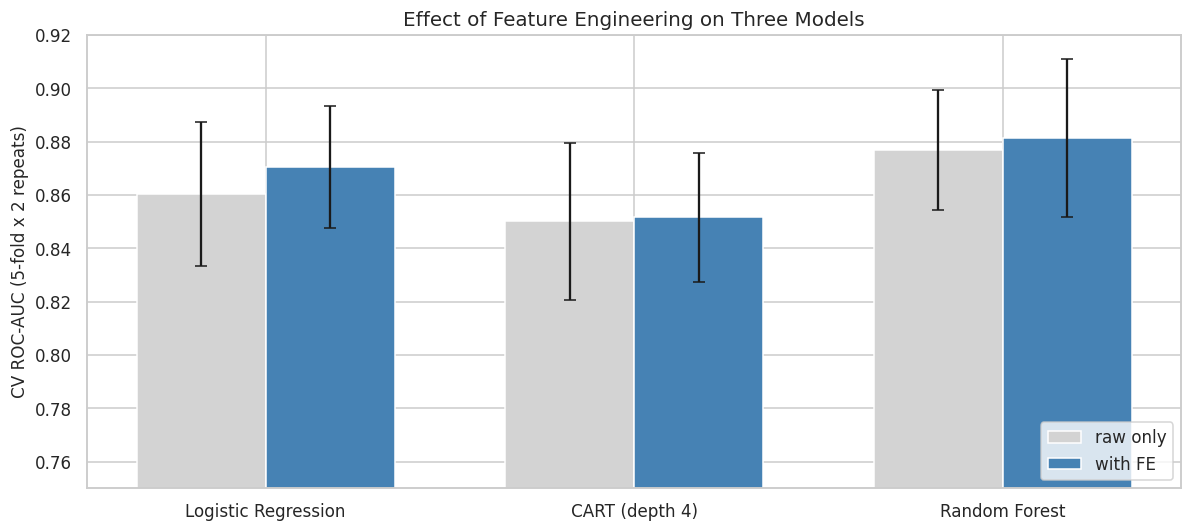

features             raw only  with FE    gain
model                                         
CART (depth 4)         0.8501   0.8516  0.0015
Logistic Regression    0.8603   0.8703  0.0100
Random Forest          0.8769   0.8814  0.0045

The CV standard deviation of the AUC is about 0.026. A gain smaller than that is not evidence of improvement:
compare each gain with the error bars before claiming that a feature helped.


In [ ]:
# ── 5.3  Does feature engineering improve cross-validated performance? ─
# Same models, same CV folds. Only use_fe changes.

fe_models = {"Logistic Regression": LogisticRegression(max_iter=2000),
             "CART (depth 4)":      DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
             "Random Forest":       RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=RANDOM_STATE)}

rows = []
for mname, model in fe_models.items():
    for use_fe in (False, True):
        r = cross_validate(make_pipeline(clone(model), use_fe=use_fe), X_train, y_train, cv=cv,
                           scoring={"acc": "accuracy", "auc": "roc_auc"})
        rows.append({"model": mname, "features": "with FE" if use_fe else "raw only",
                     "auc": r["test_auc"].mean(), "auc_std": r["test_auc"].std(), "acc": r["test_acc"].mean()})
fe_res = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(11, 5))
w = 0.35
for i, (feat, color) in enumerate([("raw only", "lightgrey"), ("with FE", "steelblue")]):
    d = fe_res[fe_res["features"] == feat]
    ax.bar(np.arange(len(d)) + (i - 0.5) * w, d["auc"], w, yerr=d["auc_std"], capsize=4,
           color=color, edgecolor="white", label=feat)
ax.set_xticks(np.arange(len(fe_models)))
ax.set_xticklabels(fe_models.keys())
ax.set_ylim(0.75, 0.92)
ax.set_ylabel("CV ROC-AUC (5-fold x 2 repeats)")
ax.set_title("Effect of Feature Engineering on Three Models")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

piv = fe_res.pivot(index="model", columns="features", values="auc")
piv["gain"] = piv["with FE"] - piv["raw only"]
print(piv.round(4).to_string())
print(f"\nThe CV standard deviation of the AUC is about {fe_res['auc_std'].mean():.3f}. A gain smaller than that is not evidence of improvement:")
print("compare each gain with the error bars before claiming that a feature helped.")

### Exercise 1: Audit, Preprocess, Engineer (new dataset)

Load the **penguins** dataset and predict the penguin's **`sex`** from the other columns:

```python
peng = sns.load_dataset("penguins")
```

1. **Audit:** show dtypes, missing counts, duplicates, and the class balance of `sex`. Which rows can never be used for training, and why (hint: look at the target)?
2. Drop those rows, then split 80% / 20% with `stratify` and `random_state=42`. Seal the test set.
3. **EDA:** one figure showing how `body_mass_g` and `bill_depth_mm` differ by `sex` (and by `species`). Add a Mann-Whitney U test for each numeric column against `sex`.
4. Build a `ColumnTransformer`: numeric columns (median impute + scale) and categorical columns `species`, `island` (most-frequent impute + one-hot). Print the output shape and confirm no `NaN` remains.
5. **Engineer** at least three features (for example `bill_ratio = bill_length_mm / bill_depth_mm`, `mass_per_flipper`, a size flag). Put them in a custom transformer like `TitanicFeatures`.
6. Compare Logistic Regression and Random Forest **with and without** your features using repeated stratified CV. Did the features help beyond one standard deviation?

```python
# Your code here
```

```
# Your answer here
```

---
## Part 6: Feature Selection

More features are not always better: irrelevant ones add noise, raise variance, and slow training. Selection can be placed **inside the pipeline**, so it is re-done on each training fold (selecting on the full data first is a classic form of leakage).

| Family | Method | Idea |
|---|---|---|
| **Filter** | `SelectKBest` with F-score or mutual information | Score each feature alone |
| **Wrapper** | `RFE` | Repeatedly train and drop the weakest feature |
| **Embedded** | `SelectFromModel` with L1 Logistic Regression or Random Forest | Selection falls out of model training |
| **Projection** | `PCA` | Replace features with fewer uncorrelated combinations (loses interpretability) |

After engineering and encoding: 26 model-ready features



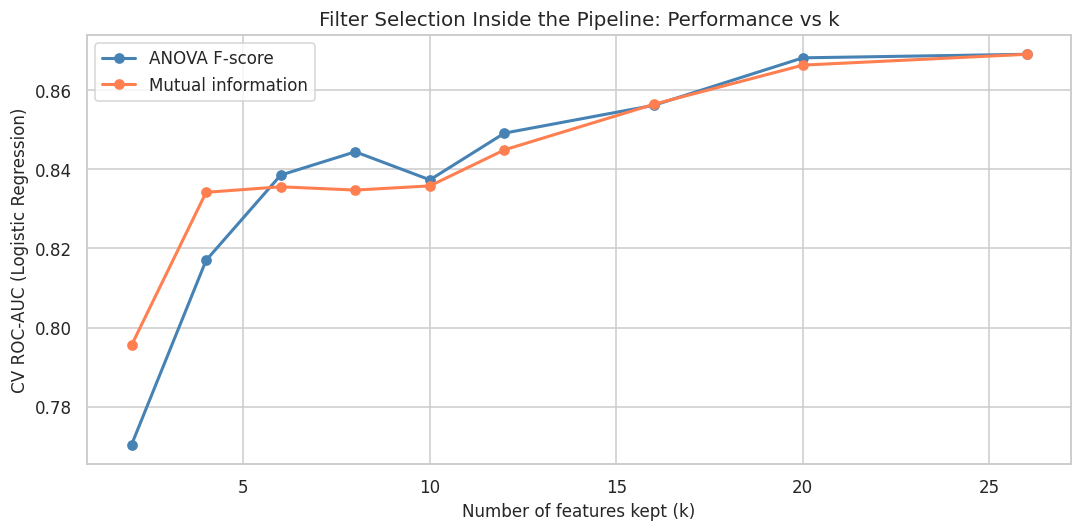

Best k for mutual information: 26  (AUC = 0.8691); all 26 features: 0.8691
Here the full feature set wins: with 26 features and 700+ rows the model is not overwhelmed by noise.
Selection can remove noise, but it is not guaranteed to help. Test it, do not assume it.


In [ ]:
# ── 6.1  Score vs number of features kept ────────────────────────────

fe_prep = Pipeline([("fe", TitanicFeatures()), ("prep", make_preprocessor())]).fit(X_train)
Xt_tr   = fe_prep.transform(X_train)
feat_names = [n.split("__", 1)[1] for n in fe_prep.get_feature_names_out()]
n_feat = len(feat_names)
print(f"After engineering and encoding: {n_feat} model-ready features\n")

ks = [2, 4, 6, 8, 10, 12, 16, 20, n_feat]
curves = {}
for label, fn in [("ANOVA F-score", f_classif),
                  ("Mutual information", partial(mutual_info_classif, random_state=RANDOM_STATE))]:
    curves[label] = [cross_val_score(
        make_pipeline(Pipeline([("sel", SelectKBest(fn, k=min(k, n_feat))), ("lr", LogisticRegression(max_iter=2000))])),
        X_train, y_train, cv=cv_fast, scoring="roc_auc").mean() for k in ks]

fig, ax = plt.subplots(figsize=(10, 5))
for (label, vals), color in zip(curves.items(), ["steelblue", "coral"]):
    ax.plot(ks, vals, "o-", color=color, linewidth=2, label=label)
ax.set_xlabel("Number of features kept (k)")
ax.set_ylabel("CV ROC-AUC (Logistic Regression)")
ax.set_title("Filter Selection Inside the Pipeline: Performance vs k")
ax.legend()
plt.tight_layout()
plt.show()

best_k = ks[int(np.argmax(curves["Mutual information"]))]
print(f"Best k for mutual information: {best_k}  (AUC = {max(curves['Mutual information']):.4f}); all {n_feat} features: {curves['Mutual information'][-1]:.4f}")
if best_k == n_feat:
    print("Here the full feature set wins: with 26 features and 700+ rows the model is not overwhelmed by noise.")
    print("Selection can remove noise, but it is not guaranteed to help. Test it, do not assume it.")
else:
    print("A compact subset matches or beats the full set, giving a simpler and more stable model.")

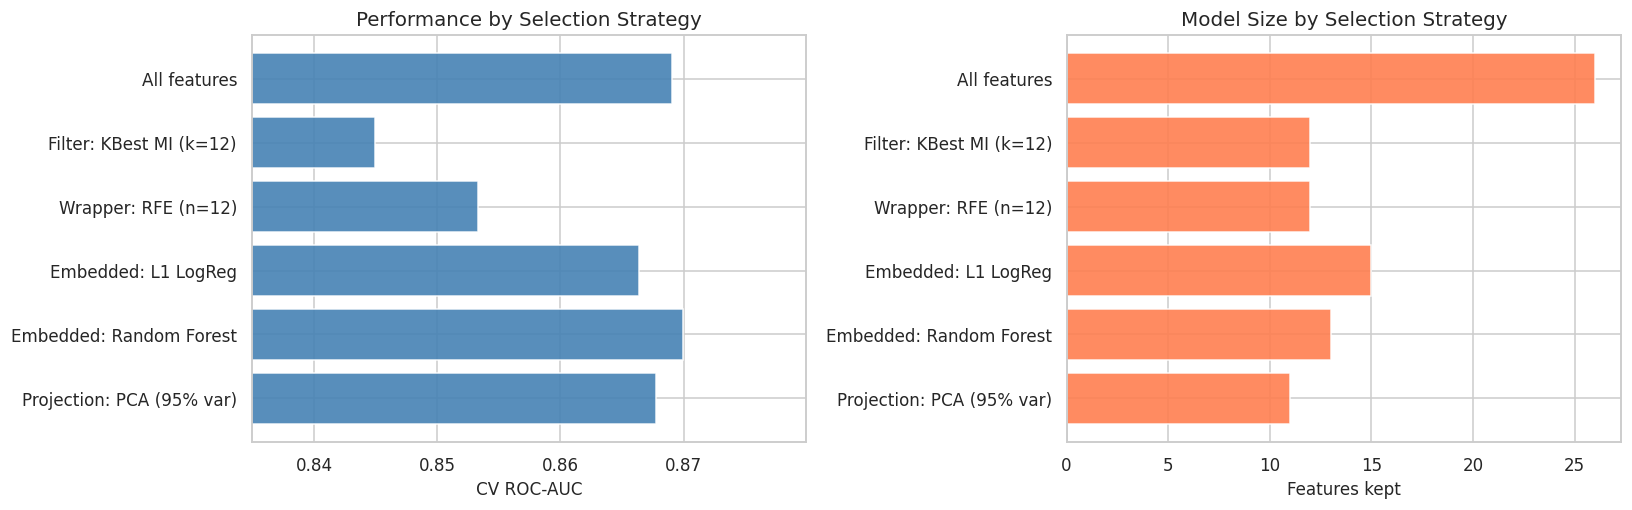

                           features_kept  cv_acc  cv_auc
strategy                                                
All features                          26  0.8104  0.8691
Filter: KBest MI (k=12)               12  0.7710  0.8449
Wrapper: RFE (n=12)                   12  0.7992  0.8533
Embedded: L1 LogReg                   15  0.8034  0.8664
Embedded: Random Forest               13  0.7977  0.8700
Projection: PCA (95% var)             11  0.8006  0.8678

Best CV AUC: Embedded: Random Forest. If 'All features' is not beaten, selection did not pay off on this dataset.


In [ ]:
# ── 6.2  Filter vs wrapper vs embedded vs PCA ────────────────────────

strategies = {
    "All features":                "passthrough",
    "Filter: KBest MI (k=12)":     SelectKBest(partial(mutual_info_classif, random_state=RANDOM_STATE), k=12),
    "Wrapper: RFE (n=12)":         RFE(LogisticRegression(max_iter=2000), n_features_to_select=12),
    "Embedded: L1 LogReg":         SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", C=0.3)),
    "Embedded: Random Forest":     SelectFromModel(RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE),
                                                   threshold="median"),
    "Projection: PCA (95% var)":   PCA(n_components=0.95, random_state=RANDOM_STATE),
}

rows = []
for name, step in strategies.items():
    clf_pipe = Pipeline([("sel", step), ("lr", LogisticRegression(max_iter=2000))])
    full = make_pipeline(clf_pipe)
    r = cross_validate(full, X_train, y_train, cv=cv_fast, scoring={"acc": "accuracy", "auc": "roc_auc"})
    fitted = clone(full).fit(X_train, y_train)
    kept = fitted.named_steps["clf"].named_steps["lr"].coef_.shape[1]
    rows.append({"strategy": name, "features_kept": kept, "cv_acc": r["test_acc"].mean(), "cv_auc": r["test_auc"].mean()})
sel_df = pd.DataFrame(rows).set_index("strategy")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].barh(sel_df.index[::-1], sel_df["cv_auc"][::-1], color="steelblue", edgecolor="white", alpha=0.9)
axes[0].set_xlim(sel_df["cv_auc"].min() - 0.01, sel_df["cv_auc"].max() + 0.01)
axes[0].set_xlabel("CV ROC-AUC"); axes[0].set_title("Performance by Selection Strategy")
axes[1].barh(sel_df.index[::-1], sel_df["features_kept"][::-1], color="coral", edgecolor="white", alpha=0.9)
axes[1].set_xlabel("Features kept"); axes[1].set_title("Model Size by Selection Strategy")
plt.tight_layout()
plt.show()

print(sel_df.round(4).to_string())
print(f"\nBest CV AUC: {sel_df['cv_auc'].idxmax()}. If 'All features' is not beaten, selection did not pay off on this dataset.")

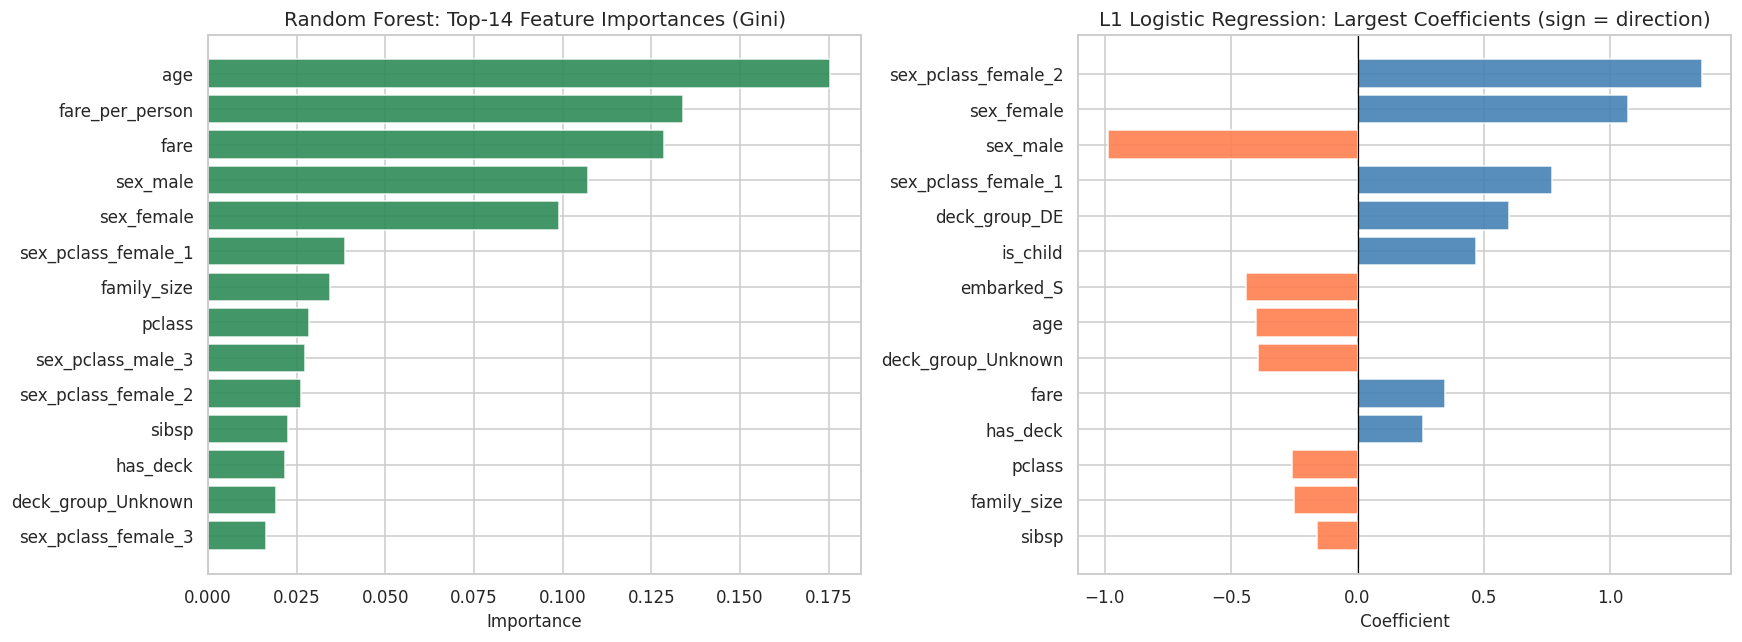

L1 regularisation set 11 of 26 coefficients exactly to zero.
Features in the top 6 of BOTH rankings: ['sex_female', 'sex_male', 'sex_pclass_female_1']
A feature that two different model families both rank highly is far more trustworthy than one a single model likes.


In [ ]:
# ── 6.3  What do embedded methods think matters? ─────────────────────

rf_imp = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(Xt_tr, y_train)
l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.3).fit(Xt_tr, y_train)

imp = pd.DataFrame({"feature": feat_names, "rf_importance": rf_imp.feature_importances_, "l1_coef": l1.coef_[0]})
top = imp.sort_values("rf_importance", ascending=False).head(14).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(top["feature"], top["rf_importance"], color="seagreen", edgecolor="white", alpha=0.9)
axes[0].set_title("Random Forest: Top-14 Feature Importances (Gini)")
axes[0].set_xlabel("Importance")

l1_sorted = imp.reindex(imp["l1_coef"].abs().sort_values(ascending=False).index).head(14).iloc[::-1]
axes[1].barh(l1_sorted["feature"], l1_sorted["l1_coef"],
             color=["coral" if v < 0 else "steelblue" for v in l1_sorted["l1_coef"]], edgecolor="white", alpha=0.9)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("L1 Logistic Regression: Largest Coefficients (sign = direction)")
axes[1].set_xlabel("Coefficient")
plt.tight_layout()
plt.show()

print(f"L1 regularisation set {int((l1.coef_[0] == 0).sum())} of {n_feat} coefficients exactly to zero.")
top_rf = set(imp.sort_values("rf_importance", ascending=False)["feature"].head(6))
top_l1 = set(imp.reindex(imp["l1_coef"].abs().sort_values(ascending=False).index)["feature"].head(6))
print(f"Features in the top 6 of BOTH rankings: {sorted(top_rf & top_l1)}")
print("A feature that two different model families both rank highly is far more trustworthy than one a single model likes.")

---
## Part 7: The Model Zoo and CART

We now compare many algorithms **under identical conditions**: same preprocessing pipeline, same repeated stratified CV folds, same metrics.

| Model | Idea | Notes |
|---|---|---|
| **Dummy** | Always predict the majority class | The floor |
| **Logistic Regression** | Linear log-odds | Fast, interpretable |
| **KNN** | Vote of nearest neighbours | Needs scaling |
| **Naive Bayes** | Independent features with Bayes' rule | Fast, strong assumptions |
| **SVM (RBF)** | Maximum-margin, non-linear kernel | Needs scaling |
| **CART** | Single decision tree (Classification And Regression Trees) | Interpretable; unstable when deep |
| **Random Forest, Extra Trees** | Many de-correlated trees, averaged | Strong default |
| **AdaBoost, Gradient Boosting, HistGB** | Trees added sequentially to fix earlier errors | Often the most accurate on tables |

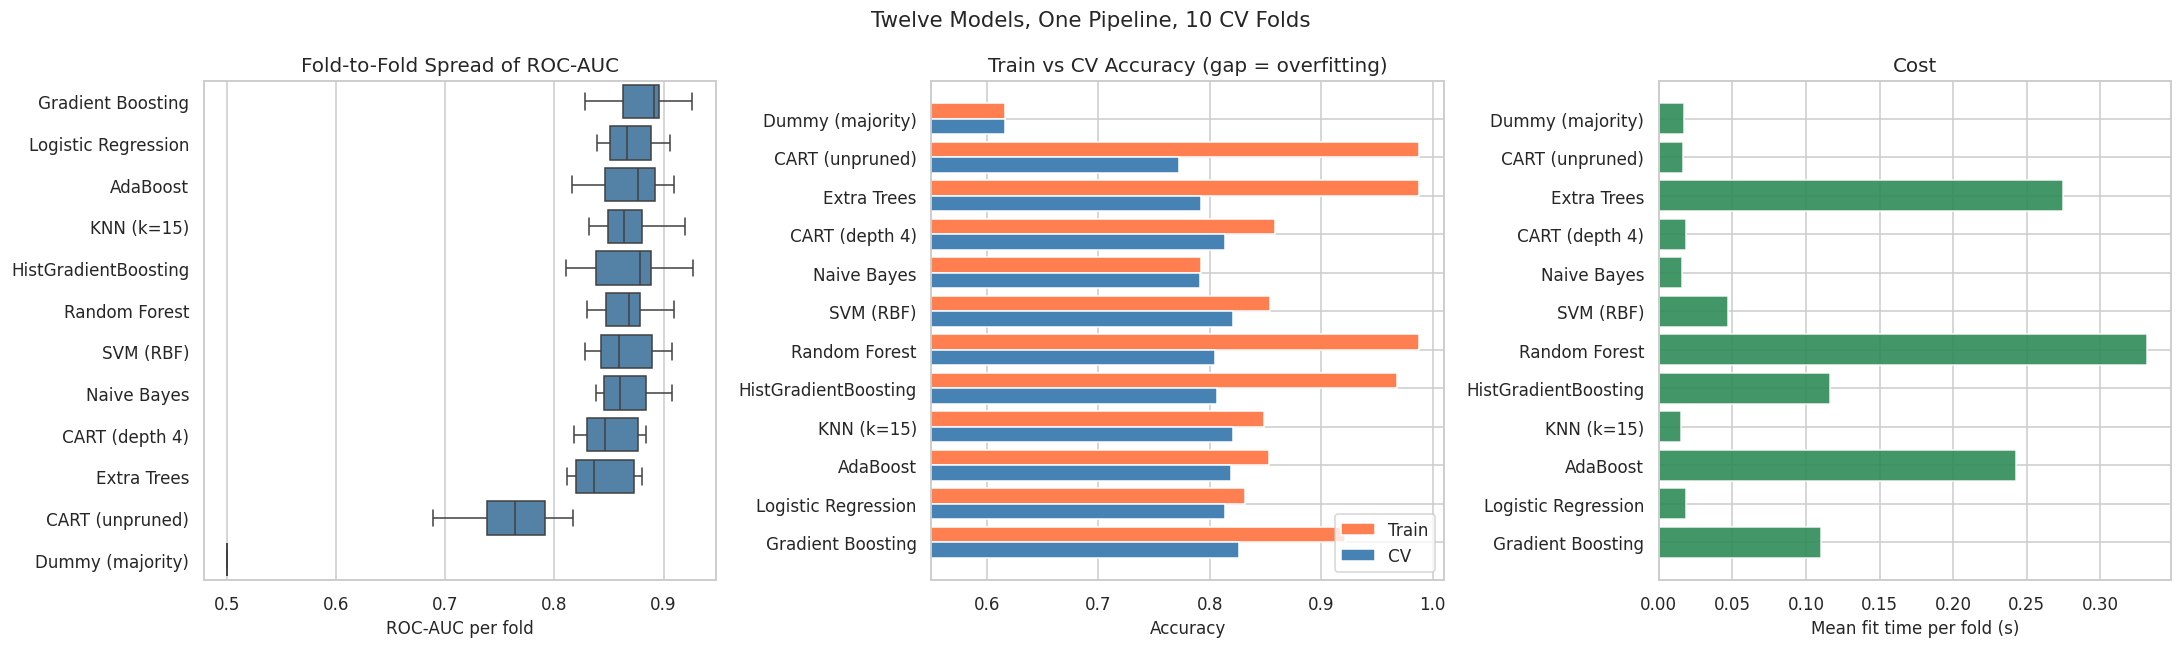

                      train_acc  cv_acc   cv_f1  cv_auc  cv_auc_std  fit_seconds
model                                                                           
Gradient Boosting        0.9210  0.8258  0.7619  0.8797      0.0292       0.1101
Logistic Regression      0.8318  0.8132  0.7335  0.8703      0.0229       0.0183
AdaBoost                 0.8531  0.8188  0.7501  0.8692      0.0301       0.2427
KNN (k=15)               0.8485  0.8209  0.7474  0.8689      0.0285       0.0153
HistGradientBoosting     0.9679  0.8068  0.7400  0.8673      0.0365       0.1161
Random Forest            0.9877  0.8048  0.7419  0.8661      0.0227       0.3318
SVM (RBF)                0.8538  0.8209  0.7457  0.8660      0.0275       0.0472
Naive Bayes              0.7923  0.7908  0.7121  0.8653      0.0226       0.0155
CART (depth 4)           0.8581  0.8139  0.7456  0.8516      0.0240       0.0182
Extra Trees              0.9877  0.7921  0.7246  0.8445      0.0267       0.2750
CART (unpruned)          0.9

In [ ]:
# ── 7.1  Compare twelve models with repeated stratified CV ───────────

zoo = {
    "Dummy (majority)":     DummyClassifier(strategy="most_frequent"),
    "Logistic Regression":  LogisticRegression(max_iter=2000),
    "KNN (k=15)":           KNeighborsClassifier(15),
    "Naive Bayes":          GaussianNB(),
    "SVM (RBF)":            SVC(probability=True, random_state=RANDOM_STATE),
    "CART (depth 4)":       DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "CART (unpruned)":      DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Extra Trees":          ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "AdaBoost":             AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting":    GradientBoostingClassifier(random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

scoring = {"acc": "accuracy", "f1": "f1", "auc": "roc_auc"}
rows, fold_auc = [], {}
for name, clf in zoo.items():
    r = cross_validate(make_pipeline(clf), X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    fold_auc[name] = r["test_auc"]
    rows.append({"model": name, "train_acc": r["train_acc"].mean(), "cv_acc": r["test_acc"].mean(),
                 "cv_f1": r["test_f1"].mean(), "cv_auc": r["test_auc"].mean(), "cv_auc_std": r["test_auc"].std(),
                 "fit_seconds": r["fit_time"].mean()})
zoo_df = pd.DataFrame(rows).set_index("model").sort_values("cv_auc", ascending=False)
order = list(zoo_df.index)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Twelve Models, One Pipeline, 10 CV Folds", fontsize=14)

sns.boxplot(data=pd.DataFrame(fold_auc)[order], orient="h", color="steelblue", ax=axes[0])
axes[0].set_xlabel("ROC-AUC per fold"); axes[0].set_title("Fold-to-Fold Spread of ROC-AUC")

y_pos = np.arange(len(order))
axes[1].barh(y_pos + 0.2, zoo_df["train_acc"], 0.4, color="coral", edgecolor="white", label="Train")
axes[1].barh(y_pos - 0.2, zoo_df["cv_acc"],    0.4, color="steelblue", edgecolor="white", label="CV")
axes[1].set_yticks(y_pos); axes[1].set_yticklabels(order); axes[1].set_xlim(0.55, 1.01)
axes[1].set_xlabel("Accuracy"); axes[1].set_title("Train vs CV Accuracy (gap = overfitting)")
axes[1].legend(loc="lower right")

axes[2].barh(order, zoo_df["fit_seconds"], color="seagreen", edgecolor="white", alpha=0.9)
axes[2].set_xlabel("Mean fit time per fold (s)"); axes[2].set_title("Cost")

plt.tight_layout()
plt.show()

print(zoo_df.round(4).to_string())

In [ ]:
# ── 7.2  Is the winner really better? A paired significance test ─────
# Both models are scored on the SAME 10 folds, so we compare them with a paired Wilcoxon signed-rank test.
# Caveat: folds share training data, so p-values are somewhat optimistic. Treat them as guidance, not proof.

top2 = order[:2]
print(f"Best two by mean CV AUC: {top2[0]}  vs  {top2[1]}")
rows = []
pairs = list(dict.fromkeys([(order[0], order[1]), (order[0], "Logistic Regression"), (order[0], "CART (unpruned)")]))
for a, b in pairs:
    diff = fold_auc[a] - fold_auc[b]
    try:
        p = stats.wilcoxon(fold_auc[a], fold_auc[b]).pvalue
    except ValueError:
        p = np.nan
    rows.append({"comparison": f"{a}  vs  {b}", "mean_AUC_diff": diff.mean(), "folds_a_wins": f"{(diff > 0).sum()}/10", "wilcoxon_p": p})
print(pd.DataFrame(rows).set_index("comparison").round(4).to_string())
print("\nIf the best two are not significantly different, prefer the simpler, faster, or more interpretable one.")

Best two by mean CV AUC: Gradient Boosting  vs  Logistic Regression
                                            mean_AUC_diff folds_a_wins  wilcoxon_p
comparison                                                                        
Gradient Boosting  vs  Logistic Regression         0.0094         7/10       0.084
Gradient Boosting  vs  CART (unpruned)             0.1182        10/10       0.002

If the best two are not significantly different, prefer the simpler, faster, or more interpretable one.


### CART Deep Dive

**CART** builds a binary tree by repeatedly choosing the **feature and threshold** that most reduces impurity:

$$\text{Gini}(t) = 1 - \sum_k p_k^2 \qquad\qquad \text{Entropy}(t) = -\sum_k p_k \log_2 p_k$$

| Control | Effect |
|---|---|
| **`max_depth`** | Limits tree height (pre-pruning) |
| **`min_samples_leaf`** | Forces leaves to be large enough to be trustworthy |
| **`ccp_alpha`** | **Cost-complexity pruning**: grow fully, then cut branches whose accuracy gain per leaf is below $\alpha$ (post-pruning) |

An unpruned tree reaches ~100% training accuracy by memorising noise. Its predictions change a lot when the training data changes (**high variance**), which is exactly what ensembles fix in Part 8.

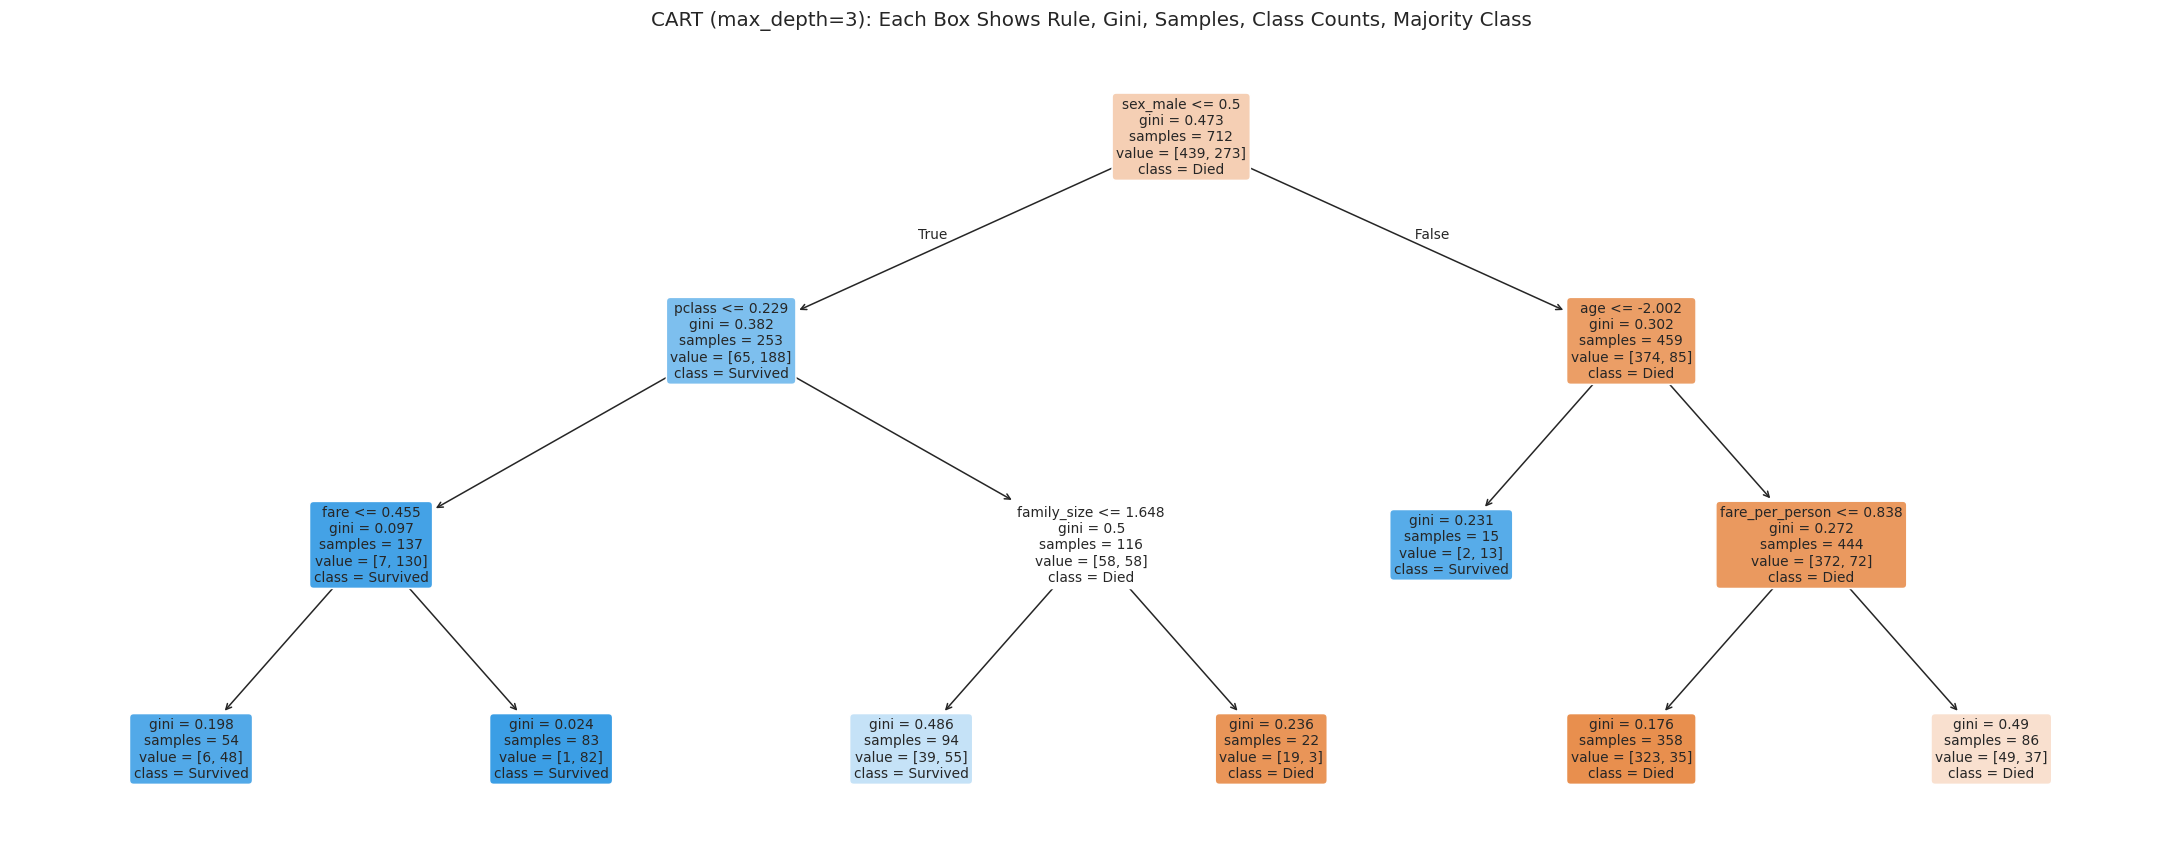

|--- sex_male <= 0.50
|   |--- pclass <= 0.23
|   |   |--- fare <= 0.46
|   |   |   |--- class: 1
|   |   |--- fare >  0.46
|   |   |   |--- class: 1
|   |--- pclass >  0.23
|   |   |--- family_size <= 1.65
|   |   |   |--- class: 1
|   |   |--- family_size >  1.65
|   |   |   |--- class: 0
|--- sex_male >  0.50
|   |--- age <= -2.00
|   |   |--- class: 1
|   |--- age >  -2.00
|   |   |--- fare_per_person <= 0.84
|   |   |   |--- class: 0
|   |   |--- fare_per_person >  0.84
|   |   |   |--- class: 0

Note: scaled features appear with scaled thresholds (e.g. a negative 'age'). For readable rules,
fit an interpretation tree on unscaled data, since trees do not need scaling.


In [ ]:
# ── 7.3  Read the tree: a depth-3 CART on the engineered features ────

tree3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=RANDOM_STATE).fit(Xt_tr, y_train)

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree3, feature_names=feat_names, class_names=["Died", "Survived"], filled=True, rounded=True,
          fontsize=9, ax=ax, impurity=True)
ax.set_title("CART (max_depth=3): Each Box Shows Rule, Gini, Samples, Class Counts, Majority Class", fontsize=13)
plt.tight_layout()
plt.show()

print(export_text(tree3, feature_names=feat_names, max_depth=3))
print("Note: scaled features appear with scaled thresholds (e.g. a negative 'age'). For readable rules,")
print("fit an interpretation tree on unscaled data, since trees do not need scaling.")

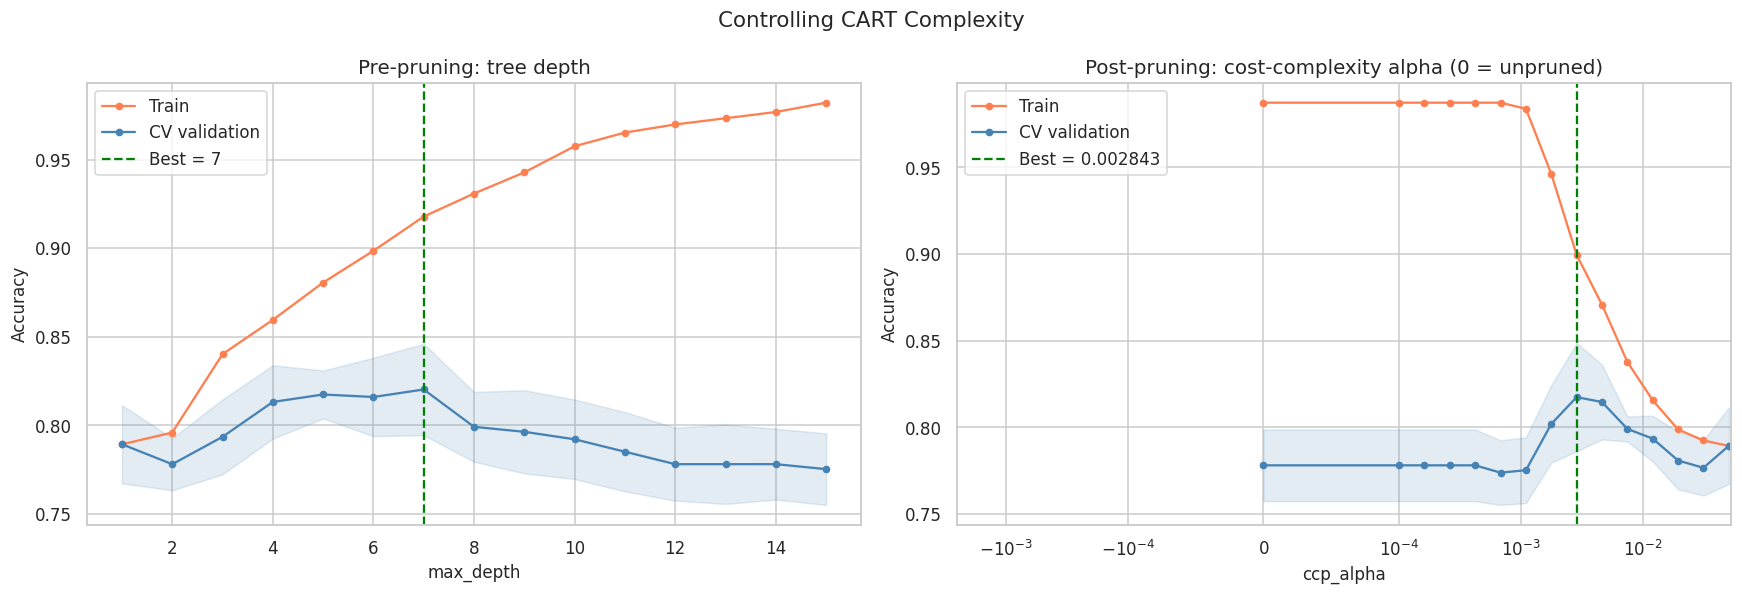

Best depth: 7 (CV acc 0.8203)   Best ccp_alpha: 0.002843 (CV acc 0.8175)
Unpruned tree: train acc 0.982 vs CV acc 0.775 at depth 15.


In [ ]:
# ── 7.4  Overfitting and pruning: depth and cost-complexity curves ───

depths = np.arange(1, 16)
tr_d, va_d = validation_curve(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), X_train, y_train,
                              param_name="clf__max_depth", param_range=depths, cv=cv_fast, scoring="accuracy")

alphas = np.concatenate([[0], np.logspace(-4, -1.3, 14)])
tr_a, va_a = validation_curve(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), X_train, y_train,
                              param_name="clf__ccp_alpha", param_range=alphas, cv=cv_fast, scoring="accuracy")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle("Controlling CART Complexity", fontsize=14)

for ax, rng_, tr, va, xl, title, logx in [
        (axes[0], depths, tr_d, va_d, "max_depth", "Pre-pruning: tree depth", False),
        (axes[1], alphas, tr_a, va_a, "ccp_alpha", "Post-pruning: cost-complexity alpha (0 = unpruned)", True)]:
    ax.plot(rng_, tr.mean(axis=1), "o-", color="coral", label="Train", markersize=4)
    ax.plot(rng_, va.mean(axis=1), "o-", color="steelblue", label="CV validation", markersize=4)
    ax.fill_between(rng_, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), color="steelblue", alpha=0.15)
    best = rng_[int(np.argmax(va.mean(axis=1)))]
    ax.axvline(best, color="green", linestyle="--", label=f"Best = {best:.4g}")
    if logx:
        ax.set_xscale("symlog", linthresh=1e-4)
    ax.set_xlabel(xl); ax.set_ylabel("Accuracy"); ax.set_title(title); ax.legend()

plt.tight_layout()
plt.show()

best_depth = int(depths[int(np.argmax(va_d.mean(axis=1)))])
best_alpha = float(alphas[int(np.argmax(va_a.mean(axis=1)))])
print(f"Best depth: {best_depth} (CV acc {va_d.mean(axis=1).max():.4f})   Best ccp_alpha: {best_alpha:.4g} (CV acc {va_a.mean(axis=1).max():.4f})")
print(f"Unpruned tree: train acc {tr_d.mean(axis=1)[-1]:.3f} vs CV acc {va_d.mean(axis=1)[-1]:.3f} at depth 15.")

---
## Part 8: Ensembles

An **ensemble** combines several models so that their **errors partly cancel**. It works only when the members are **accurate enough** and **different enough**.

| Strategy | How members are built | Combined by | Reduces |
|---|---|---|---|
| **Bagging** (and Random Forest) | Independent models on bootstrap samples (RF also randomises features) | Average / vote | **Variance** |
| **Boosting** | Models added **sequentially**, each focusing on the previous errors | Weighted sum | **Bias** (and variance with shrinkage) |
| **Voting** | **Different** model types trained on the same data | Hard: majority class. Soft: average probabilities | Individual weaknesses |
| **Stacking** | Different models; a **meta-learner** learns how to weigh their out-of-fold predictions | Learned combination | Both, at higher cost |

### 8.1 Bagging: Averaging Away Variance

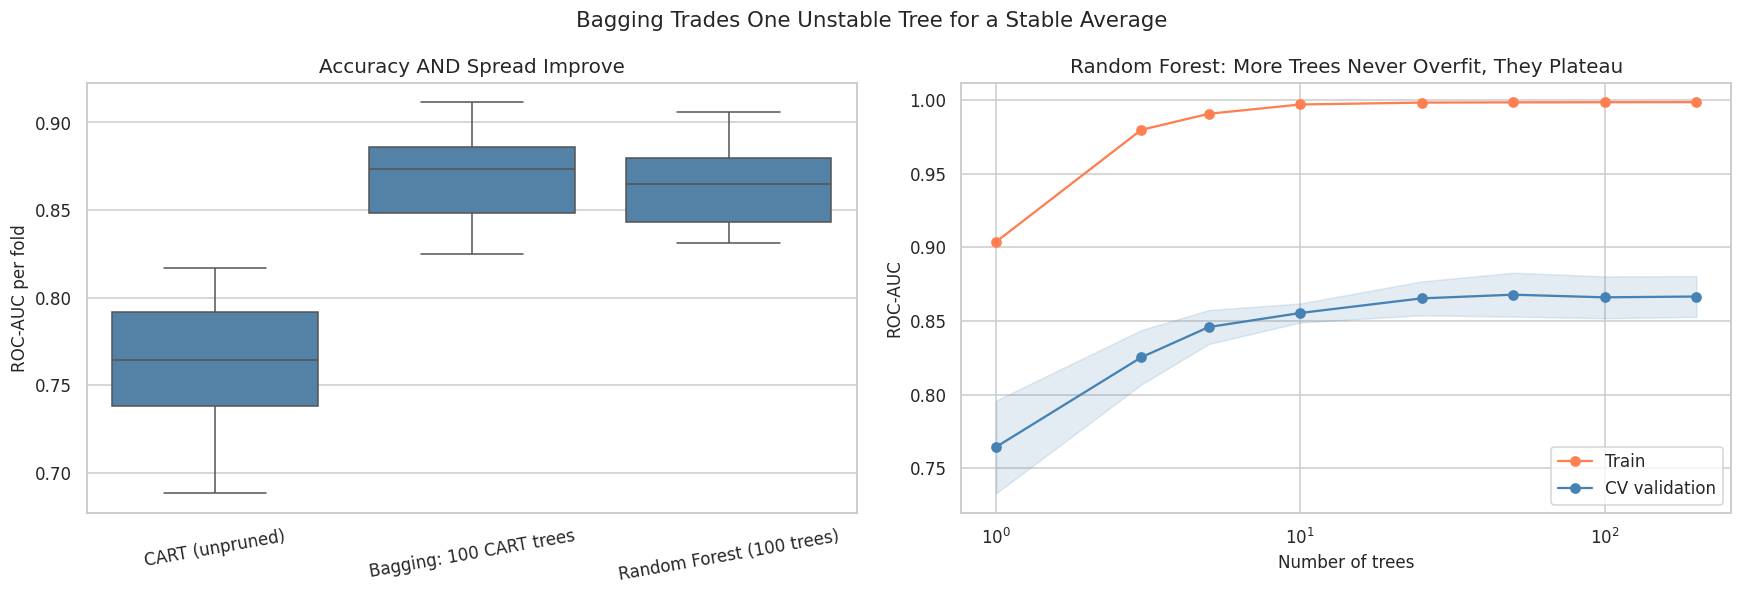

CART (unpruned)              AUC = 0.7615 ± 0.0388
Bagging: 100 CART trees      AUC = 0.8676 ± 0.0258
Random Forest (100 trees)    AUC = 0.8636 ± 0.0225


In [ ]:
# ── 8.1  One tree vs bagged trees vs a random forest ─────────────────

variance_models = {
    "CART (unpruned)":            DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Bagging: 100 CART trees":    BaggingClassifier(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                                    n_estimators=100, random_state=RANDOM_STATE),
    "Random Forest (100 trees)":  RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
}
bag_auc = {}
for name, m in variance_models.items():
    bag_auc[name] = cross_val_score(make_pipeline(m), X_train, y_train, cv=cv, scoring="roc_auc")

n_trees = [1, 3, 5, 10, 25, 50, 100, 200]
tr_n, va_n = validation_curve(make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)), X_train, y_train,
                              param_name="clf__n_estimators", param_range=n_trees, cv=cv_fast, scoring="roc_auc")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle("Bagging Trades One Unstable Tree for a Stable Average", fontsize=14)

sns.boxplot(data=pd.DataFrame(bag_auc), color="steelblue", ax=axes[0])
axes[0].set_ylabel("ROC-AUC per fold"); axes[0].set_title("Accuracy AND Spread Improve")
axes[0].tick_params(axis="x", rotation=10)

axes[1].plot(n_trees, tr_n.mean(axis=1), "o-", color="coral", label="Train")
axes[1].plot(n_trees, va_n.mean(axis=1), "o-", color="steelblue", label="CV validation")
axes[1].fill_between(n_trees, va_n.mean(axis=1) - va_n.std(axis=1), va_n.mean(axis=1) + va_n.std(axis=1), color="steelblue", alpha=0.15)
axes[1].set_xscale("log"); axes[1].set_xlabel("Number of trees"); axes[1].set_ylabel("ROC-AUC")
axes[1].set_title("Random Forest: More Trees Never Overfit, They Plateau"); axes[1].legend()

plt.tight_layout()
plt.show()

for name, v in bag_auc.items():
    print(f"{name:28s} AUC = {v.mean():.4f} ± {v.std():.4f}")

### 8.2 Boosting: Fixing Mistakes Sequentially

Gradient boosting adds one small tree at a time, each fitted to the **errors of the ensemble so far**. Two key knobs interact:

- **`n_estimators`**: more trees = more fitting power (and more overfitting risk).
- **`learning_rate`** (shrinkage): how much each tree contributes. Smaller rates need more trees but generalise better.

**Early stopping** picks the number of trees where **validation** performance peaks.

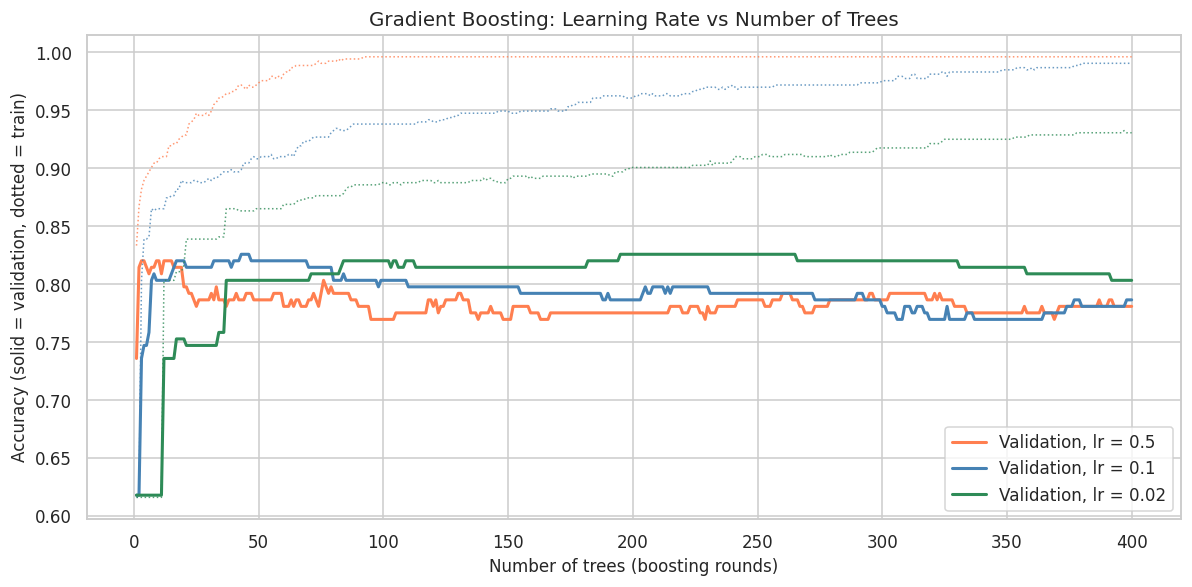

learning_rate = 0.5    best validation accuracy 0.8202 at 3 trees
learning_rate = 0.1    best validation accuracy 0.8258 at 43 trees
learning_rate = 0.02   best validation accuracy 0.8258 at 195 trees

HistGradientBoosting with built-in early stopping chose 48 of a possible 1000 trees automatically.
Dotted train curves keep rising while validation flattens or falls: that gap is overfitting.


In [ ]:
# ── 8.2  Boosting curves on a held-out validation slice of the TRAIN set ─

X_a, X_v, y_a, y_v = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=1)
fe_p = Pipeline([("fe", TitanicFeatures()), ("prep", make_preprocessor())]).fit(X_a)
Xa, Xv = fe_p.transform(X_a), fe_p.transform(X_v)

fig, ax = plt.subplots(figsize=(11, 5.5))
best_iters = {}
for lr, color in [(0.5, "coral"), (0.1, "steelblue"), (0.02, "seagreen")]:
    gb = GradientBoostingClassifier(n_estimators=400, learning_rate=lr, max_depth=3, random_state=RANDOM_STATE).fit(Xa, y_a)
    tr = [accuracy_score(y_a, p) for p in gb.staged_predict(Xa)]
    va = [accuracy_score(y_v, p) for p in gb.staged_predict(Xv)]
    ax.plot(range(1, 401), va, color=color, linewidth=2, label=f"Validation, lr = {lr}")
    ax.plot(range(1, 401), tr, color=color, linewidth=1, linestyle=":", alpha=0.8)
    best_iters[lr] = (int(np.argmax(va)) + 1, max(va))
ax.set_xlabel("Number of trees (boosting rounds)")
ax.set_ylabel("Accuracy (solid = validation, dotted = train)")
ax.set_title("Gradient Boosting: Learning Rate vs Number of Trees")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

for lr, (it, acc) in best_iters.items():
    print(f"learning_rate = {lr:<5}  best validation accuracy {acc:.4f} at {it} trees")

hgb_es = HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.15,
                                        n_iter_no_change=20, random_state=RANDOM_STATE).fit(Xa, y_a)
print(f"\nHistGradientBoosting with built-in early stopping chose {hgb_es.n_iter_} of a possible 1000 trees automatically.")
print("Dotted train curves keep rising while validation flattens or falls: that gap is overfitting.")

### 8.3 Voting and 8.4 Stacking

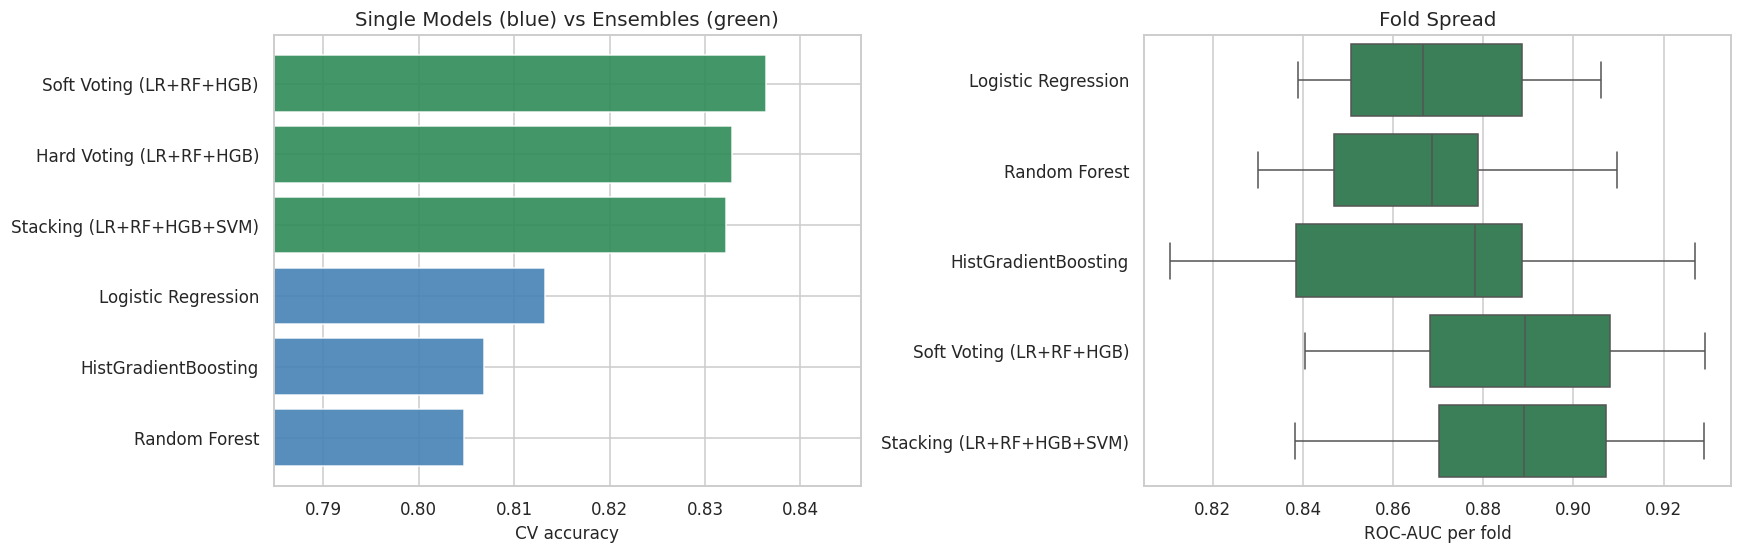

                          cv_acc   cv_f1  cv_auc  cv_auc_std
model                                                       
Soft Voting (LR+RF+HGB)   0.8364  0.7702  0.8860      0.0271
Hard Voting (LR+RF+HGB)   0.8329  0.7670     NaN         NaN
Stacking (LR+RF+HGB+SVM)  0.8322  0.7642  0.8859      0.0274
Logistic Regression       0.8132  0.7335  0.8703      0.0229
HistGradientBoosting      0.8068  0.7400  0.8673      0.0365
Random Forest             0.8048  0.7419  0.8661      0.0227

Hard voting has no probabilities, so it has no ROC-AUC. Ensembles usually give small, stable gains,
not miracles: with only a few hundred rows, the best single models already sit near the ceiling.


In [ ]:
# ── 8.3 / 8.4  Voting (hard and soft) and Stacking ───────────────────

def base_models():
    return [("lr",  LogisticRegression(max_iter=2000)),
            ("rf",  RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=RANDOM_STATE)),
            ("hgb", HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=150, random_state=RANDOM_STATE))]

ensembles = {
    "Hard Voting (LR+RF+HGB)": VotingClassifier(base_models(), voting="hard"),
    "Soft Voting (LR+RF+HGB)": VotingClassifier(base_models(), voting="soft"),
    "Stacking (LR+RF+HGB+SVM)": StackingClassifier(
        estimators=base_models() + [("svm", SVC(probability=True, random_state=RANDOM_STATE))],
        final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method="predict_proba"),
}

rows = []
for name, clf in ensembles.items():
    scoring_e = {"acc": "accuracy", "f1": "f1"} if "Hard" in name else scoring     # hard voting has no probabilities
    r = cross_validate(make_pipeline(clf), X_train, y_train, cv=cv, scoring=scoring_e)
    if "test_auc" in r:
        fold_auc[name] = r["test_auc"]
    rows.append({"model": name, "cv_acc": r["test_acc"].mean(), "cv_f1": r["test_f1"].mean(),
                 "cv_auc": r["test_auc"].mean() if "test_auc" in r else np.nan,
                 "cv_auc_std": r["test_auc"].std() if "test_auc" in r else np.nan})
ens_df = pd.DataFrame(rows).set_index("model")

singles = zoo_df.loc[["Logistic Regression", "Random Forest", "HistGradientBoosting"],
                     ["cv_acc", "cv_f1", "cv_auc", "cv_auc_std"]]
compare = pd.concat([singles, ens_df]).sort_values("cv_acc", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
colors_ = ["seagreen" if i in ens_df.index else "steelblue" for i in compare.index]
axes[0].barh(compare.index[::-1], compare["cv_acc"][::-1], color=colors_[::-1], edgecolor="white", alpha=0.9)
axes[0].set_xlim(compare["cv_acc"].min() - 0.02, compare["cv_acc"].max() + 0.01)
axes[0].set_xlabel("CV accuracy"); axes[0].set_title("Single Models (blue) vs Ensembles (green)")

ens_auc = {k: v for k, v in fold_auc.items() if k in list(ens_df.index) + ["Logistic Regression", "Random Forest", "HistGradientBoosting"]}
sns.boxplot(data=pd.DataFrame(ens_auc), orient="h", color="seagreen", ax=axes[1])
axes[1].set_xlabel("ROC-AUC per fold"); axes[1].set_title("Fold Spread")
plt.tight_layout()
plt.show()

print(compare.round(4).to_string())
print("\nHard voting has no probabilities, so it has no ROC-AUC. Ensembles usually give small, stable gains,")
print("not miracles: with only a few hundred rows, the best single models already sit near the ceiling.")

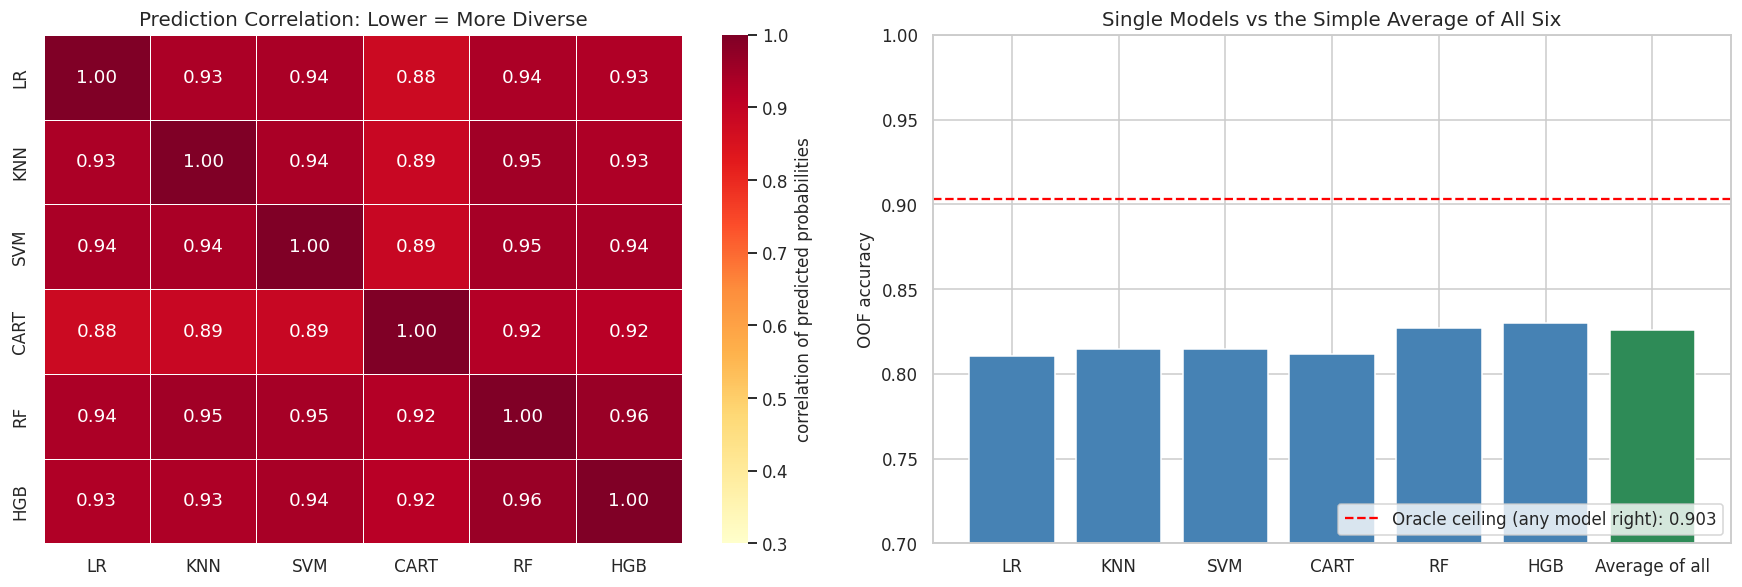

Best single OOF accuracy: 0.8301 (HGB)   Averaged ensemble: 0.8258   Oracle: 0.9031
Averaging ALL six models, weak ones included, did not beat the best single model: ensembles need members that are
accurate as well as diverse. Soft voting over a well-chosen few (Part 8.3) is the better recipe.
The oracle line is the gap diversity could in principle close. Models that make the SAME mistakes cannot fix each other.


In [ ]:
# ── 8.5  Why ensembles help: diversity of out-of-fold predictions ────
# Out-of-fold (OOF) probabilities: every training row is predicted by a model that never saw it.

div_models = {"LR":   LogisticRegression(max_iter=2000),
              "KNN":  KNeighborsClassifier(15),
              "SVM":  SVC(probability=True, random_state=RANDOM_STATE),
              "CART": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
              "RF":   RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=RANDOM_STATE),
              "HGB":  HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=150, random_state=RANDOM_STATE)}
oof = pd.DataFrame({n: cross_val_predict(make_pipeline(m), X_train, y_train, cv=cv_fast, method="predict_proba")[:, 1]
                    for n, m in div_models.items()})

correct = oof.apply(lambda col: ((col >= 0.5).astype(int) == y_train.values))
mean_proba = oof.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.heatmap(oof.corr(), annot=True, fmt=".2f", cmap="YlOrRd", vmin=0.3, vmax=1, linewidths=0.5, ax=axes[0],
            cbar_kws={"label": "correlation of predicted probabilities"})
axes[0].set_title("Prediction Correlation: Lower = More Diverse")

single_acc = correct.mean()
oracle = correct.any(axis=1).mean()
ens_acc = accuracy_score(y_train, (mean_proba >= 0.5).astype(int))
axes[1].bar(list(single_acc.index) + ["Average of all"], list(single_acc.values) + [ens_acc],
            color=["steelblue"] * len(single_acc) + ["seagreen"], edgecolor="white")
axes[1].axhline(oracle, color="red", linestyle="--", label=f"Oracle ceiling (any model right): {oracle:.3f}")
axes[1].set_ylim(0.7, 1.0); axes[1].set_ylabel("OOF accuracy")
axes[1].set_title("Single Models vs the Simple Average of All Six")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Best single OOF accuracy: {single_acc.max():.4f} ({single_acc.idxmax()})   Averaged ensemble: {ens_acc:.4f}   Oracle: {oracle:.4f}")
if ens_acc <= single_acc.max():
    print("Averaging ALL six models, weak ones included, did not beat the best single model: ensembles need members that are")
    print("accurate as well as diverse. Soft voting over a well-chosen few (Part 8.3) is the better recipe.")
print("The oracle line is the gap diversity could in principle close. Models that make the SAME mistakes cannot fix each other.")

### Exercise 2: Model Zoo and Ensembles (penguins)

Using the **penguins** pipeline you built in Exercise 1 (predict `sex`):

1. Compare **at least eight models** with `RepeatedStratifiedKFold(5, 2)` and `roc_auc` plus `accuracy`: Dummy, Logistic Regression, KNN, SVM, CART (depth 3), Random Forest, HistGradientBoosting, and one more of your choice.
2. Plot a **boxplot of per-fold ROC-AUC** sorted by mean, and a **train vs CV accuracy** bar chart. Which models overfit most?
3. Build a **soft Voting** classifier and a **Stacking** classifier from your three best models. Do they beat the best single model by more than one standard deviation?
4. Run a **paired Wilcoxon test** between the best single model and the best ensemble. Is the difference significant?
5. For CART only, plot a **validation curve over `max_depth`** (1 to 12) and a **`ccp_alpha`** curve. Which pruning level do you choose?
6. Compute **out-of-fold probabilities** for 5 models, plot their correlation heatmap, and decide which two models are the most useful pair to combine.

```python
# Your code here
```

```
# Your answer here
```

---
## Part 9: Hyperparameter Tuning

| Method | How it searches | When to use |
|---|---|---|
| **Grid search** | Every combination of a small grid | Few parameters; CART |
| **Random search** | Random draws from distributions | Many parameters; boosting, forests (usually beats grid for equal budget) |
| **Nested CV** | Tune in an inner loop, score in an outer loop | An **unbiased** estimate of "tuned model" performance |

> **The optimism trap:** the best CV score found by a search is a **biased-high** estimate, because you picked the winner among many noisy scores. Nested CV removes that bias.

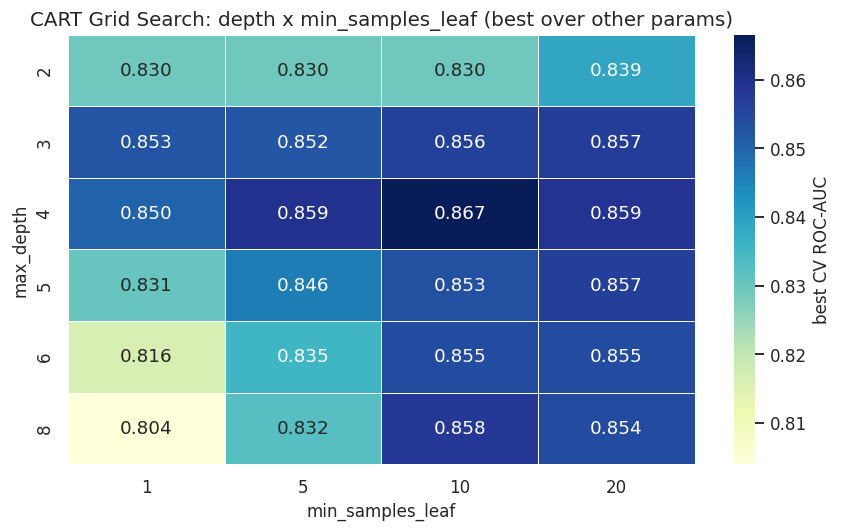

Best CART: {'clf__ccp_alpha': 0, 'clf__criterion': 'gini', 'clf__max_depth': 4, 'clf__min_samples_leaf': 10}
Best CV ROC-AUC: 0.8665   (default CART depth 4: 0.8516)


In [ ]:
# ── 9.1  Grid search for CART ────────────────────────────────────────

cart_grid = {
    "clf__max_depth":        [2, 3, 4, 5, 6, 8],
    "clf__min_samples_leaf": [1, 5, 10, 20],
    "clf__ccp_alpha":        [0, 0.002],
    "clf__criterion":        ["gini", "entropy"],
}
gs_cart = GridSearchCV(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), cart_grid,
                       cv=cv_fast, scoring="roc_auc")
gs_cart.fit(X_train, y_train)

res = pd.DataFrame(gs_cart.cv_results_)
heat = res.groupby(["param_clf__max_depth", "param_clf__min_samples_leaf"])["mean_test_score"].max().unstack().astype(float)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu", linewidths=0.5, ax=ax, cbar_kws={"label": "best CV ROC-AUC"})
ax.set_title("CART Grid Search: depth x min_samples_leaf (best over other params)")
ax.set_xlabel("min_samples_leaf"); ax.set_ylabel("max_depth")
plt.tight_layout()
plt.show()

tuned_cart = gs_cart.best_estimator_
print(f"Best CART: {gs_cart.best_params_}")
print(f"Best CV ROC-AUC: {gs_cart.best_score_:.4f}   (default CART depth 4: {zoo_df.loc['CART (depth 4)', 'cv_auc']:.4f})")

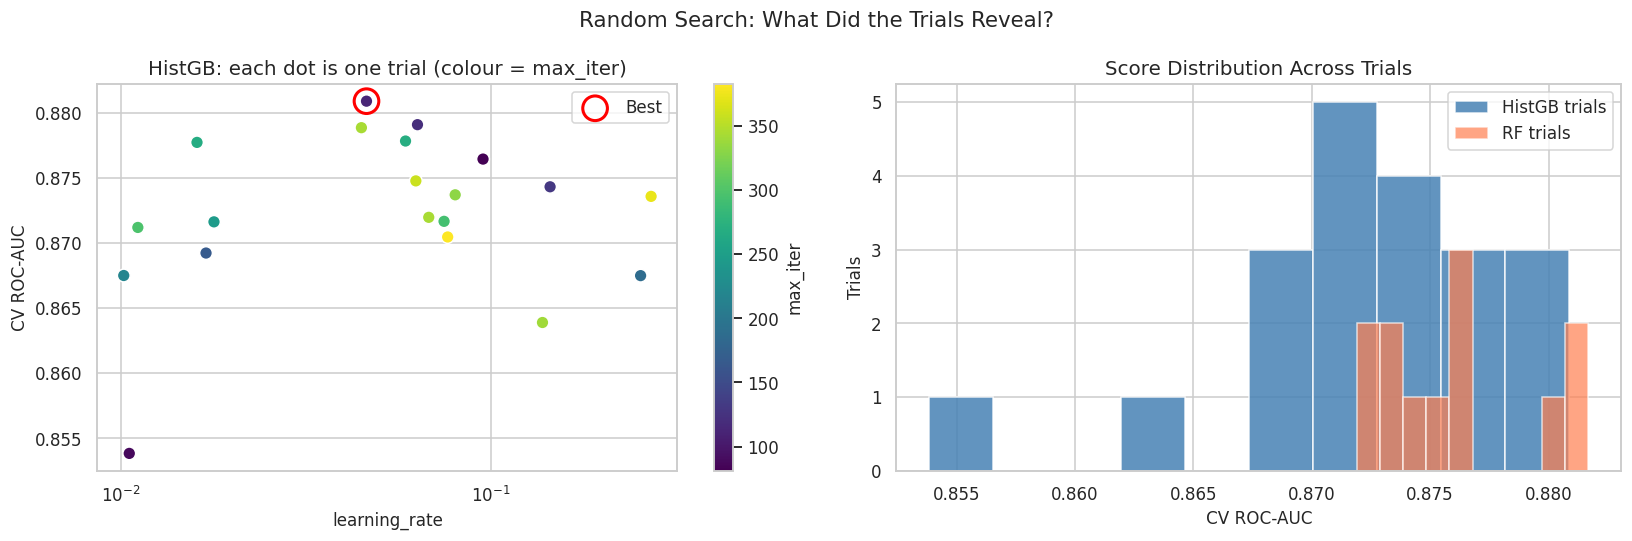

HistGB best CV AUC: 0.8809   (default: 0.8673)
RF     best CV AUC: 0.8817   (default: 0.8661)
Spread across trials is often wider than the gain over defaults: tuning helps, but it is not a magic wand.


In [ ]:
# ── 9.2  Randomised search for HistGradientBoosting and Random Forest ─

hgb_dist = {
    "clf__learning_rate":     loguniform(0.01, 0.3),
    "clf__max_iter":          randint(80, 400),
    "clf__max_leaf_nodes":    randint(6, 40),
    "clf__min_samples_leaf":  randint(5, 50),
    "clf__l2_regularization": loguniform(1e-3, 10),
}
rs_hgb = RandomizedSearchCV(make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE)), hgb_dist,
                            n_iter=20, cv=cv_fast, scoring="roc_auc", random_state=RANDOM_STATE)
rs_hgb.fit(X_train, y_train)

rf_dist = {
    "clf__n_estimators":     randint(100, 300),
    "clf__max_depth":        [3, 5, 8, 12, None],
    "clf__min_samples_leaf": randint(1, 15),
    "clf__max_features":     ["sqrt", "log2", 0.5, 0.8],
}
rs_rf = RandomizedSearchCV(make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)), rf_dist,
                           n_iter=12, cv=cv_fast, scoring="roc_auc", random_state=RANDOM_STATE)
rs_rf.fit(X_train, y_train)

tuned_hgb, tuned_rf = rs_hgb.best_estimator_, rs_rf.best_estimator_

r_h = pd.DataFrame(rs_hgb.cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Random Search: What Did the Trials Reveal?", fontsize=14)
sc = axes[0].scatter(r_h["param_clf__learning_rate"].astype(float), r_h["mean_test_score"], c=r_h["param_clf__max_iter"].astype(float),
                     cmap="viridis", s=70, edgecolors="white")
axes[0].set_xscale("log"); axes[0].set_xlabel("learning_rate"); axes[0].set_ylabel("CV ROC-AUC")
axes[0].set_title("HistGB: each dot is one trial (colour = max_iter)")
plt.colorbar(sc, ax=axes[0], label="max_iter")
axes[0].scatter([rs_hgb.best_params_["clf__learning_rate"]], [rs_hgb.best_score_], s=260, facecolors="none",
                edgecolors="red", linewidth=2, label="Best")
axes[0].legend()

axes[1].hist(r_h["mean_test_score"], bins=10, color="steelblue", edgecolor="white", alpha=0.85, label="HistGB trials")
axes[1].hist(pd.DataFrame(rs_rf.cv_results_)["mean_test_score"], bins=10, color="coral", edgecolor="white", alpha=0.7, label="RF trials")
axes[1].set_xlabel("CV ROC-AUC"); axes[1].set_ylabel("Trials"); axes[1].set_title("Score Distribution Across Trials")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"HistGB best CV AUC: {rs_hgb.best_score_:.4f}   (default: {zoo_df.loc['HistGradientBoosting', 'cv_auc']:.4f})")
print(f"RF     best CV AUC: {rs_rf.best_score_:.4f}   (default: {zoo_df.loc['Random Forest', 'cv_auc']:.4f})")
print("Spread across trials is often wider than the gain over defaults: tuning helps, but it is not a magic wand.")

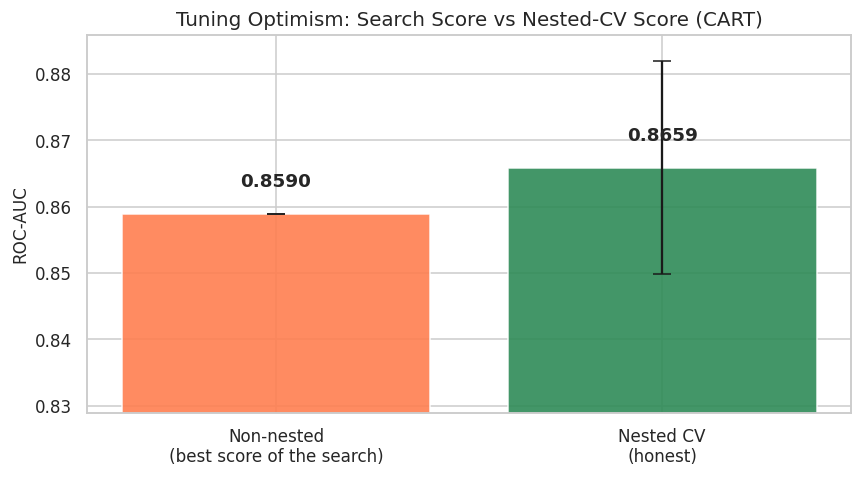

Non-nested best score: 0.8590   Nested CV: 0.8659 ± 0.0161
In theory the non-nested score is optimistic. With a small grid and noisy folds the gap can be tiny or even reversed, as here:
the nested estimate (with its ± spread) is still the one to report.


In [ ]:
# ── 9.3  Nested CV: an honest estimate of a TUNED model ──────────────

inner = StratifiedKFold(5, shuffle=True, random_state=1)
outer = StratifiedKFold(5, shuffle=True, random_state=2)
small_grid = {"clf__max_depth": [3, 4, 6], "clf__min_samples_leaf": [1, 10, 20], "clf__ccp_alpha": [0, 0.004]}

inner_search = GridSearchCV(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), small_grid,
                            cv=inner, scoring="roc_auc")
nested = cross_val_score(inner_search, X_train, y_train, cv=outer, scoring="roc_auc")
inner_search.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(["Non-nested\n(best score of the search)", "Nested CV\n(honest)"], [inner_search.best_score_, nested.mean()],
       yerr=[0, nested.std()], capsize=6, color=["coral", "seagreen"], edgecolor="white", alpha=0.9)
for i, v in enumerate([inner_search.best_score_, nested.mean()]):
    ax.text(i, v + 0.004, f"{v:.4f}", ha="center", fontweight="bold")
ax.set_ylim(min(inner_search.best_score_, nested.mean()) - 0.03, max(inner_search.best_score_, nested.mean()) + 0.02)
ax.set_ylabel("ROC-AUC")
ax.set_title("Tuning Optimism: Search Score vs Nested-CV Score (CART)")
plt.tight_layout()
plt.show()

print(f"Non-nested best score: {inner_search.best_score_:.4f}   Nested CV: {nested.mean():.4f} ± {nested.std():.4f}")
if inner_search.best_score_ > nested.mean():
    print("The non-nested score is higher, as theory predicts: the same folds were used to pick AND to score the winner.")
else:
    print("In theory the non-nested score is optimistic. With a small grid and noisy folds the gap can be tiny or even reversed, as here:")
    print("the nested estimate (with its ± spread) is still the one to report.")

---
## Part 10: Final Evaluation on the Sealed Test Set

Now, and only now, we open the test set. Discipline:

1. **Choose the final model using cross-validation on the training set only**, and write the choice down **before** looking at test results.
2. Evaluate **once**. Report everything honestly, including candidates that lost.
3. Go beyond one number: discrimination, calibration, threshold, uncertainty, subgroup behaviour, and interpretation.

| Metric | Answers |
|---|---|
| **Accuracy / Balanced accuracy** | Overall hit rate / hit rate averaged over classes |
| **Precision, Recall (sensitivity), Specificity** | Of predicted survivors how many are real / of real survivors how many found / same for non-survivors |
| **F1** | Harmonic mean of precision and recall |
| **MCC, Cohen's kappa** | Single-number agreement scores that stay honest under imbalance |
| **ROC-AUC** | Ranking quality over all thresholds |
| **PR-AUC (average precision)** | Same, focused on the positive class; better for rare positives |
| **Log loss, Brier score** | Quality of the **probabilities** themselves (lower = better) |

In [ ]:
# ── 10.1  Candidates and the pre-registered choice ───────────────────

candidates = {
    "Logistic Regression":    make_pipeline(LogisticRegression(max_iter=2000)),
    "CART (tuned)":           clone(tuned_cart),
    "Random Forest (tuned)":  clone(tuned_rf),
    "HistGB (tuned)":         clone(tuned_hgb),
    "Soft Voting":            make_pipeline(VotingClassifier(base_models(), voting="soft")),
    "Stacking":               make_pipeline(StackingClassifier(
                                  estimators=base_models() + [("svm", SVC(probability=True, random_state=RANDOM_STATE))],
                                  final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method="predict_proba")),
}

# Selection uses CROSS-VALIDATION ON THE TRAINING SET ONLY. (Tuned models carry a little optimism; see Part 9.3.)
cv_auc = {name: cross_val_score(clone(p), X_train, y_train, cv=cv_fast, scoring="roc_auc").mean()
          for name, p in candidates.items()}
final_name = max(cv_auc, key=cv_auc.get)

print("Cross-validated ROC-AUC on the training set:")
for name, v in sorted(cv_auc.items(), key=lambda kv: -kv[1]):
    print(f"  {name:24s} {v:.4f}{'   <-- chosen' if name == final_name else ''}")
print(f"\nFinal model chosen BEFORE touching the test set: {final_name}")

fitted = {name: clone(p).fit(X_train, y_train) for name, p in candidates.items()}
final_model = fitted[final_name]
proba = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}

Cross-validated ROC-AUC on the training set:
  Soft Voting              0.8878   <-- chosen
  Stacking                 0.8872
  Random Forest (tuned)    0.8817
  HistGB (tuned)           0.8809
  Logistic Regression      0.8691
  CART (tuned)             0.8665

Final model chosen BEFORE touching the test set: Soft Voting


                       accuracy  balanced_acc  precision  recall  specificity     f1    mcc  kappa  roc_auc  pr_auc  log_loss  brier
Logistic Regression       0.810         0.775      0.843   0.623        0.927  0.717  0.594  0.579    0.851   0.796     0.454  0.139
CART (tuned)              0.760         0.737      0.710   0.638        0.836  0.672  0.485  0.483    0.819   0.768     0.501  0.164
Random Forest (tuned)     0.765         0.736      0.737   0.609        0.864  0.667  0.493  0.488    0.830   0.811     0.488  0.155
HistGB (tuned)            0.816         0.793      0.800   0.696        0.891  0.744  0.605  0.601    0.838   0.801     0.478  0.149
Soft Voting               0.804         0.773      0.815   0.638        0.909  0.715  0.580  0.570    0.844   0.827     0.451  0.140
Stacking                  0.793         0.764      0.786   0.638        0.891  0.704  0.555  0.548    0.844   0.826     0.443  0.140


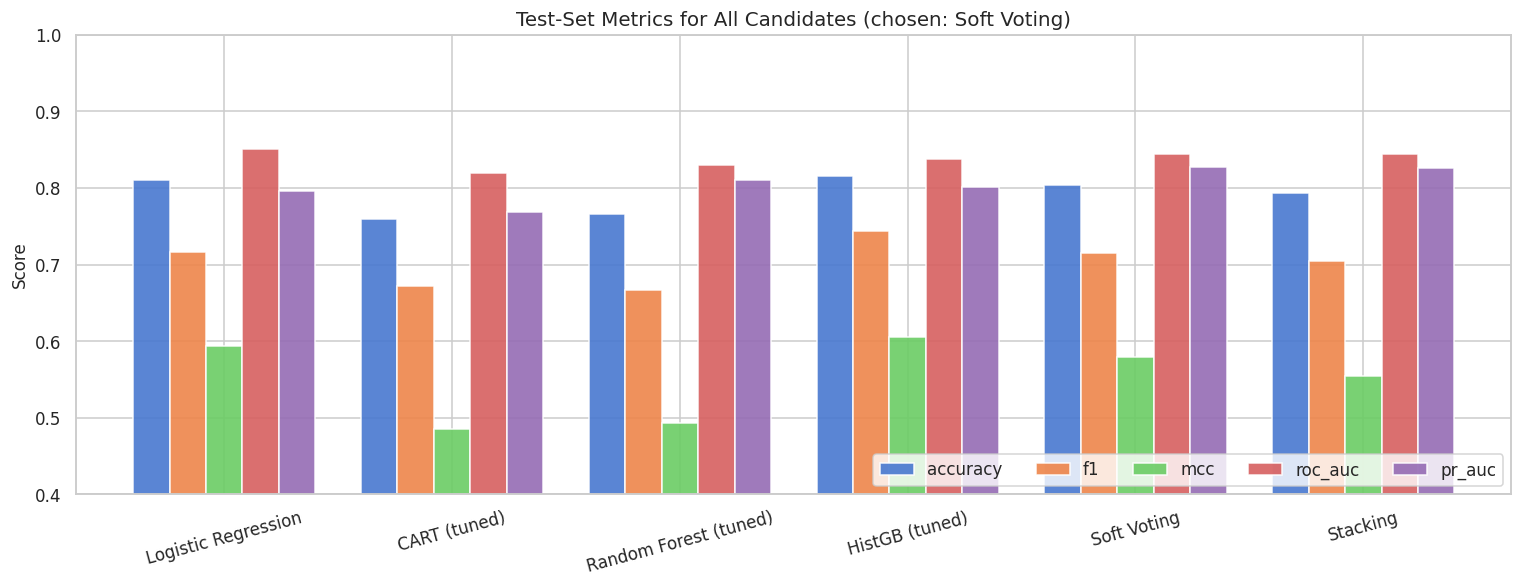


The test set has only 179 rows: one passenger changes accuracy by 0.56 points.
Differences between top candidates are usually within that noise. Part 10.7 puts error bars on it.


In [ ]:
# ── 10.2  The full metric table on the test set ──────────────────────

def full_metrics(y_true, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"accuracy":     accuracy_score(y_true, pred),
            "balanced_acc": balanced_accuracy_score(y_true, pred),
            "precision":    precision_score(y_true, pred, zero_division=0),
            "recall":       recall_score(y_true, pred),
            "specificity":  tn / (tn + fp),
            "f1":           f1_score(y_true, pred),
            "mcc":          matthews_corrcoef(y_true, pred),
            "kappa":        cohen_kappa_score(y_true, pred),
            "roc_auc":      roc_auc_score(y_true, p),
            "pr_auc":       average_precision_score(y_true, p),
            "log_loss":     log_loss(y_true, p),
            "brier":        brier_score_loss(y_true, p)}

test_df = pd.DataFrame({name: full_metrics(y_test, p) for name, p in proba.items()}).T
print(test_df.round(3).to_string())

show = ["accuracy", "f1", "mcc", "roc_auc", "pr_auc"]
fig, ax = plt.subplots(figsize=(14, 5.5))
test_df[show].plot(kind="bar", ax=ax, edgecolor="white", alpha=0.9, width=0.8)
ax.set_ylim(0.4, 1.0)
ax.set_ylabel("Score"); ax.set_title(f"Test-Set Metrics for All Candidates (chosen: {final_name})")
ax.tick_params(axis="x", rotation=15); ax.legend(ncol=5, loc="lower right")
plt.tight_layout()
plt.show()

print(f"\nThe test set has only {len(y_test)} rows: one passenger changes accuracy by {100 / len(y_test):.2f} points.")
print("Differences between top candidates are usually within that noise. Part 10.7 puts error bars on it.")

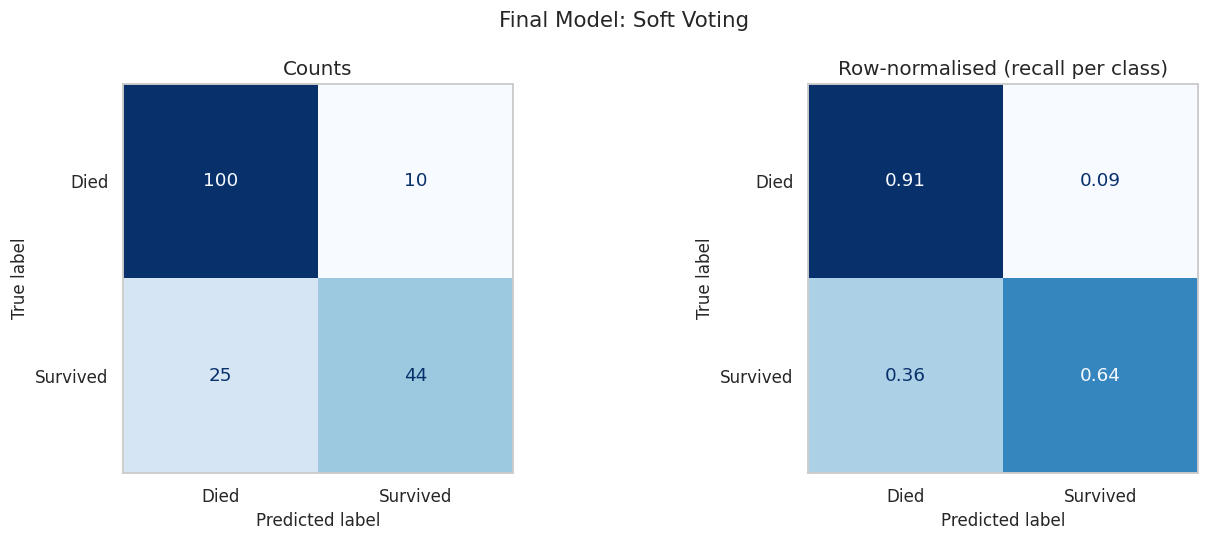

              precision    recall  f1-score   support

        Died      0.800     0.909     0.851       110
    Survived      0.815     0.638     0.715        69

    accuracy                          0.804       179
   macro avg      0.807     0.773     0.783       179
weighted avg      0.806     0.804     0.799       179



In [ ]:
# ── 10.3  Confusion matrix and per-class report for the final model ──

pred_final = (proba[final_name] >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f"Final Model: {final_name}", fontsize=14)
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, display_labels=["Died", "Survived"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Counts"); axes[0].grid(False)
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, display_labels=["Died", "Survived"],
                                        normalize="true", cmap="Blues", colorbar=False, ax=axes[1], values_format=".2f")
axes[1].set_title("Row-normalised (recall per class)"); axes[1].grid(False)
plt.tight_layout()
plt.show()

print(classification_report(y_test, pred_final, target_names=["Died", "Survived"], digits=3))

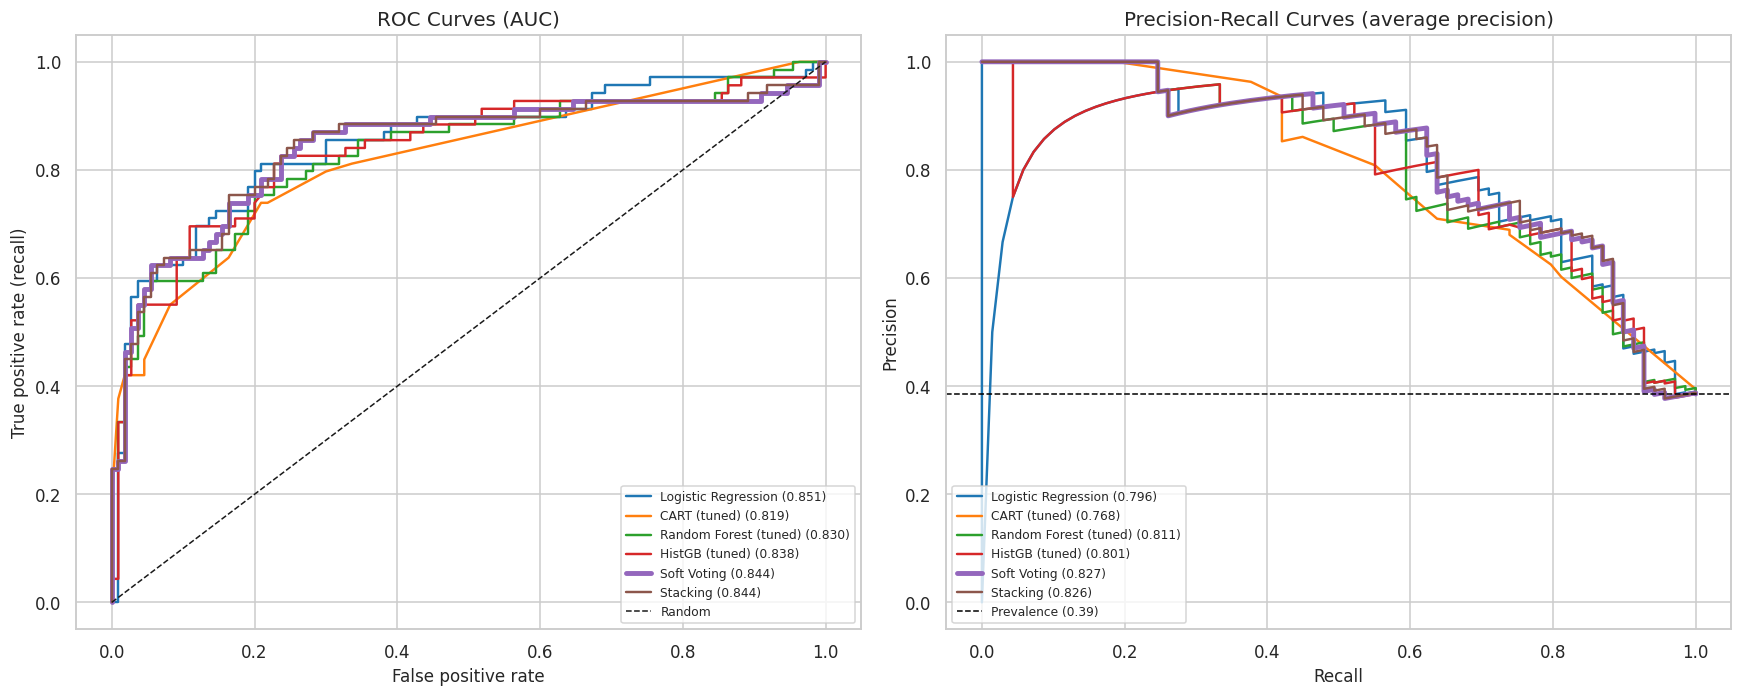

ROC can look flattering when the positive class is not the focus. The PR curve shows the precision price of each recall level.


In [ ]:
# ── 10.4  ROC and precision-recall curves for every candidate ────────

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
palette = sns.color_palette("tab10", len(proba))
for (name, p), color in zip(proba.items(), palette):
    lw = 3.2 if name == final_name else 1.6
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=color, linewidth=lw, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=color, linewidth=lw, label=f"{name} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Random")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC Curves (AUC)"); axes[0].legend(loc="lower right", fontsize=8)
axes[1].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label=f"Prevalence ({y_test.mean():.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curves (average precision)"); axes[1].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

print("ROC can look flattering when the positive class is not the focus. The PR curve shows the precision price of each recall level.")

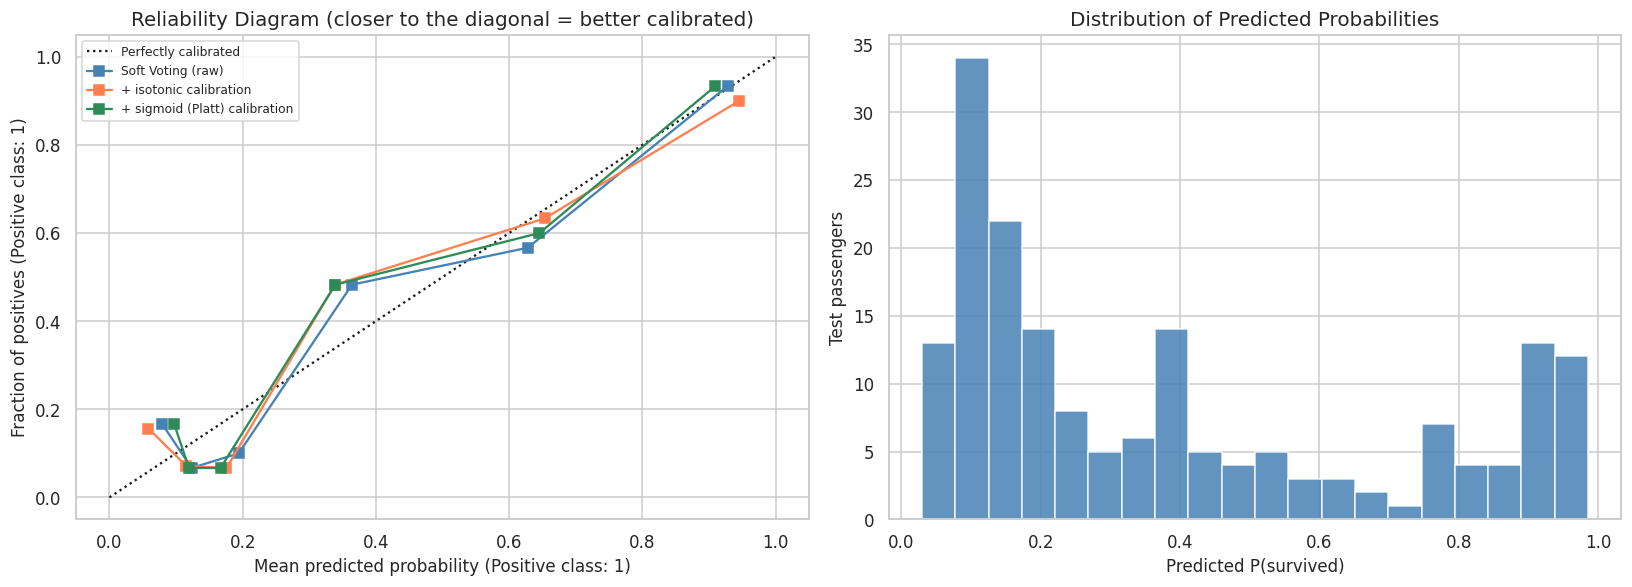

Soft Voting (raw)                Brier = 0.1400   log loss = 0.4509   AUC = 0.8439
+ isotonic calibration           Brier = 0.1410   log loss = 0.4780   AUC = 0.8435
+ sigmoid (Platt) calibration    Brier = 0.1384   log loss = 0.4406   AUC = 0.8432

Calibration changes the probabilities, not the ranking, so AUC barely moves.
Here the raw model was already close to calibrated, so recalibration gives no real gain (isotonic can even hurt on small data).


In [ ]:
# ── 10.5  Calibration: can we trust the predicted probabilities? ─────
# A calibrated model that says "70%" is right about 70% of the time. Ranking quality (AUC) does not guarantee that.

cal_iso = CalibratedClassifierCV(clone(final_model), method="isotonic", cv=5).fit(X_train, y_train)
cal_sig = CalibratedClassifierCV(clone(final_model), method="sigmoid", cv=5).fit(X_train, y_train)
cal_probs = {f"{final_name} (raw)": proba[final_name],
             "+ isotonic calibration": cal_iso.predict_proba(X_test)[:, 1],
             "+ sigmoid (Platt) calibration": cal_sig.predict_proba(X_test)[:, 1]}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for (name, p), color in zip(cal_probs.items(), ["steelblue", "coral", "seagreen"]):
    CalibrationDisplay.from_predictions(y_test, p, n_bins=6, strategy="quantile", name=name, ax=axes[0], color=color)
axes[0].set_title("Reliability Diagram (closer to the diagonal = better calibrated)")
axes[0].legend(loc="upper left", fontsize=8)
axes[1].hist(proba[final_name], bins=20, color="steelblue", edgecolor="white", alpha=0.85)
axes[1].set_xlabel("Predicted P(survived)"); axes[1].set_ylabel("Test passengers")
axes[1].set_title("Distribution of Predicted Probabilities")
plt.tight_layout()
plt.show()

for name, p in cal_probs.items():
    print(f"{name:32s} Brier = {brier_score_loss(y_test, p):.4f}   log loss = {log_loss(y_test, p):.4f}   AUC = {roc_auc_score(y_test, p):.4f}")
bs = {k: brier_score_loss(y_test, v) for k, v in cal_probs.items()}
print("\nCalibration changes the probabilities, not the ranking, so AUC barely moves.")
if min(bs.values()) >= bs[f"{final_name} (raw)"] - 0.003:
    print("Here the raw model was already close to calibrated, so recalibration gives no real gain (isotonic can even hurt on small data).")
else:
    print("Recalibration lowered the Brier score, so use the calibrated probabilities if you act on the numbers.")

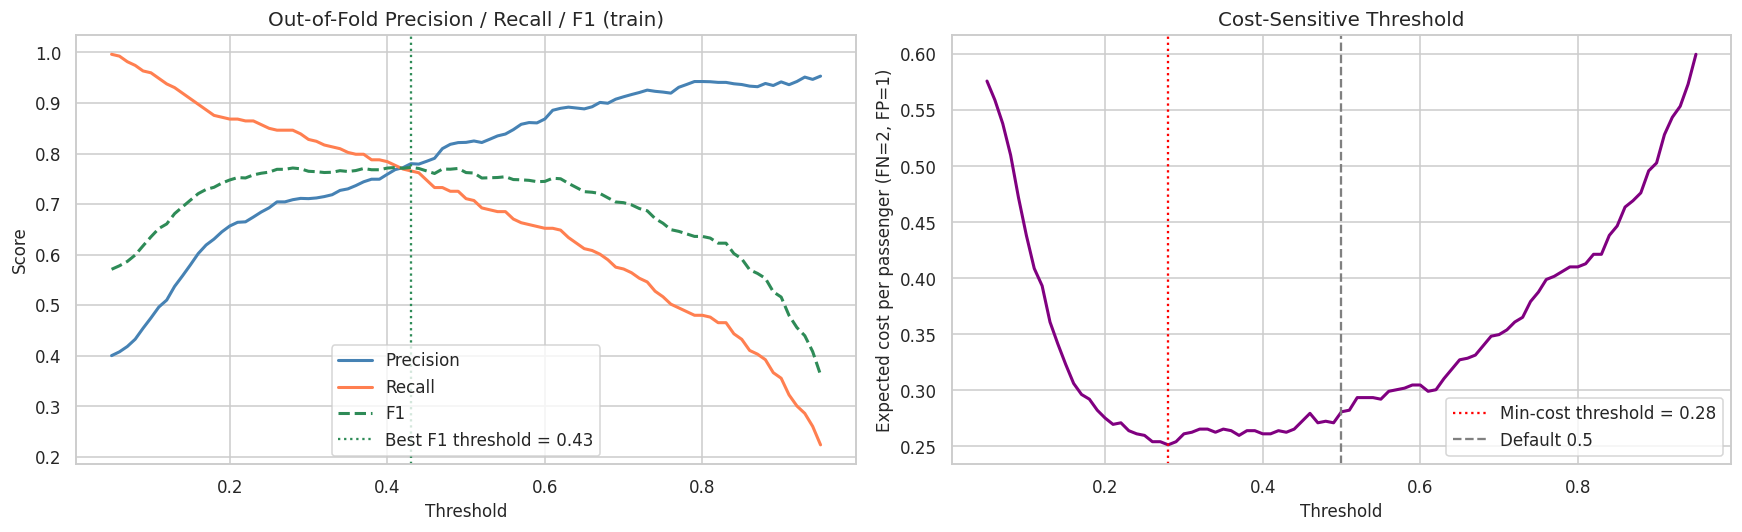

Test @ default 0.5        recall = 0.638  precision = 0.815  F1 = 0.715  FN = 25  FP = 10  cost/passenger = 0.335
Test @ best F1 (0.43)     recall = 0.667  precision = 0.754  F1 = 0.708  FN = 23  FP = 15  cost/passenger = 0.341
Test @ min cost (0.28)    recall = 0.855  precision = 0.670  F1 = 0.752  FN = 10  FP = 29  cost/passenger = 0.274

The threshold was chosen on TRAIN predictions, so these test numbers are an honest check of that choice.


In [ ]:
# ── 10.6  Choosing a decision threshold WITHOUT touching the test set ─
# 0.5 is a convention, not a law. Pick the threshold on out-of-fold TRAIN predictions, using an explicit cost:
# here we assume missing a survivor (false negative) costs twice as much as a false alarm (false positive).

oof_final = cross_val_predict(clone(final_model), X_train, y_train, cv=cv_fast, method="predict_proba")[:, 1]
COST_FN, COST_FP = 2.0, 1.0

grid_thr = np.linspace(0.05, 0.95, 91)
f1_curve, cost_curve, prec_curve, rec_curve = [], [], [], []
for t in grid_thr:
    pr = (oof_final >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pr, labels=[0, 1]).ravel()
    f1_curve.append(f1_score(y_train, pr, zero_division=0))
    prec_curve.append(precision_score(y_train, pr, zero_division=0)); rec_curve.append(recall_score(y_train, pr))
    cost_curve.append((COST_FN * fn + COST_FP * fp) / len(y_train))

thr_f1   = grid_thr[int(np.argmax(f1_curve))]
thr_cost = grid_thr[int(np.argmin(cost_curve))]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(grid_thr, prec_curve, color="steelblue", linewidth=2, label="Precision")
axes[0].plot(grid_thr, rec_curve,  color="coral", linewidth=2, label="Recall")
axes[0].plot(grid_thr, f1_curve,   color="seagreen", linewidth=2, linestyle="--", label="F1")
axes[0].axvline(thr_f1, color="seagreen", linestyle=":", label=f"Best F1 threshold = {thr_f1:.2f}")
axes[0].set_xlabel("Threshold"); axes[0].set_ylabel("Score"); axes[0].set_title("Out-of-Fold Precision / Recall / F1 (train)"); axes[0].legend()
axes[1].plot(grid_thr, cost_curve, color="purple", linewidth=2)
axes[1].axvline(thr_cost, color="red", linestyle=":", label=f"Min-cost threshold = {thr_cost:.2f}")
axes[1].axvline(0.5, color="grey", linestyle="--", label="Default 0.5")
axes[1].set_xlabel("Threshold"); axes[1].set_ylabel(f"Expected cost per passenger (FN={COST_FN:g}, FP={COST_FP:g})")
axes[1].set_title("Cost-Sensitive Threshold"); axes[1].legend()
plt.tight_layout()
plt.show()

for label, t in [("default 0.5", 0.5), (f"best F1 ({thr_f1:.2f})", thr_f1), (f"min cost ({thr_cost:.2f})", thr_cost)]:
    m = full_metrics(y_test, proba[final_name], t)
    pr = (proba[final_name] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pr, labels=[0, 1]).ravel()
    print(f"Test @ {label:18s} recall = {m['recall']:.3f}  precision = {m['precision']:.3f}  F1 = {m['f1']:.3f}  "
          f"FN = {fn}  FP = {fp}  cost/passenger = {(COST_FN * fn + COST_FP * fp) / len(y_test):.3f}")
print("\nThe threshold was chosen on TRAIN predictions, so these test numbers are an honest check of that choice.")

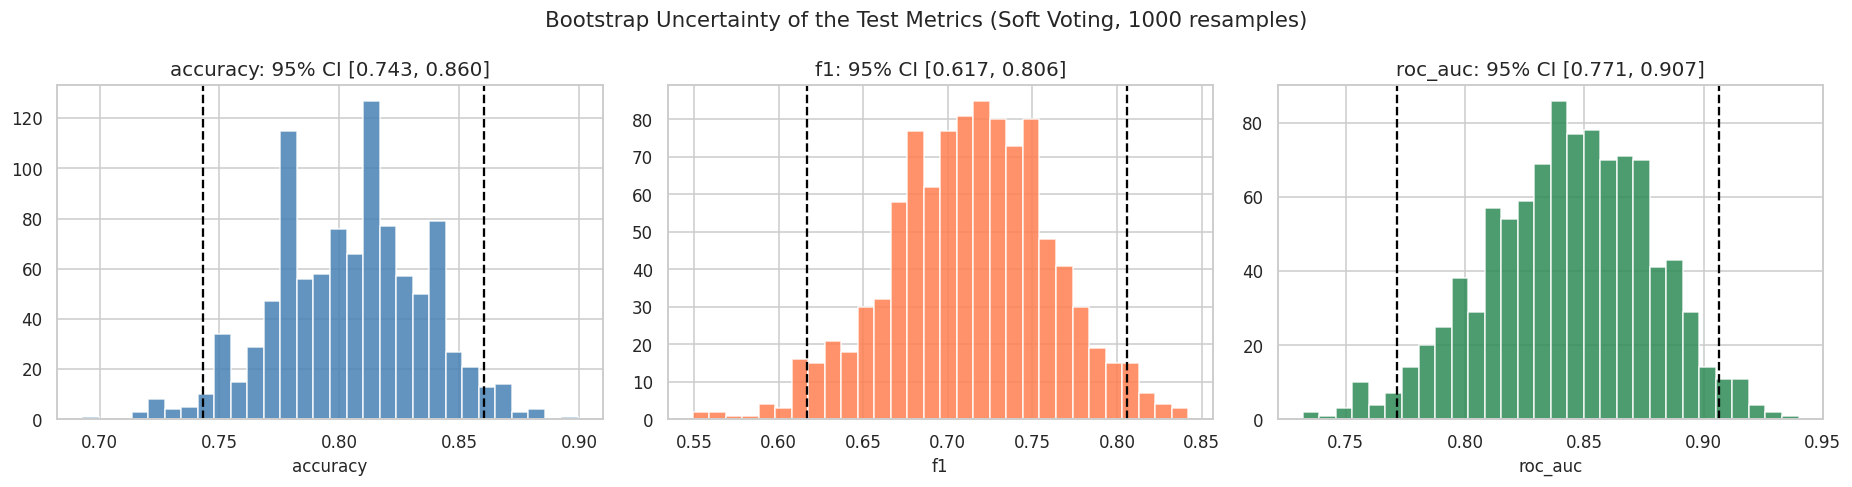

McNemar: Soft Voting vs Logistic Regression:  only Logistic Regression right = 6,  only Soft Voting right = 5,  exact p = 1.000
A wide confidence interval or a non-significant McNemar p-value means the test set cannot separate the top models.


In [ ]:
# ── 10.7  How sure are we? Bootstrap confidence intervals and McNemar ─

rng = np.random.default_rng(RANDOM_STATE)
n_t = len(y_test)
yt = y_test.values
boot = {"accuracy": [], "f1": [], "roc_auc": []}
for _ in range(1000):
    ix = rng.integers(0, n_t, n_t)
    if len(np.unique(yt[ix])) < 2:
        continue
    pr = (proba[final_name][ix] >= 0.5).astype(int)
    boot["accuracy"].append(accuracy_score(yt[ix], pr))
    boot["f1"].append(f1_score(yt[ix], pr))
    boot["roc_auc"].append(roc_auc_score(yt[ix], proba[final_name][ix]))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
fig.suptitle(f"Bootstrap Uncertainty of the Test Metrics ({final_name}, 1000 resamples)", fontsize=14)
for ax, (metric, vals), color in zip(axes, boot.items(), ["steelblue", "coral", "seagreen"]):
    lo_, hi_ = np.percentile(vals, [2.5, 97.5])
    ax.hist(vals, bins=30, color=color, edgecolor="white", alpha=0.85)
    ax.axvline(lo_, color="black", linestyle="--"); ax.axvline(hi_, color="black", linestyle="--")
    ax.set_title(f"{metric}: 95% CI [{lo_:.3f}, {hi_:.3f}]")
    ax.set_xlabel(metric)
plt.tight_layout()
plt.show()

# McNemar's exact test: do two models make DIFFERENT errors more often than chance would explain?
ref_name = "Logistic Regression" if final_name != "Logistic Regression" else "CART (tuned)"
ok_f = (proba[final_name] >= 0.5).astype(int) == yt
ok_r = (proba[ref_name]   >= 0.5).astype(int) == yt
b, c = int((ok_r & ~ok_f).sum()), int((~ok_r & ok_f).sum())
p_mc = stats.binomtest(min(b, c), b + c, 0.5).pvalue if (b + c) > 0 else 1.0
print(f"McNemar: {final_name} vs {ref_name}:  only {ref_name} right = {b},  only {final_name} right = {c},  exact p = {p_mc:.3f}")
print("A wide confidence interval or a non-significant McNemar p-value means the test set cannot separate the top models.")

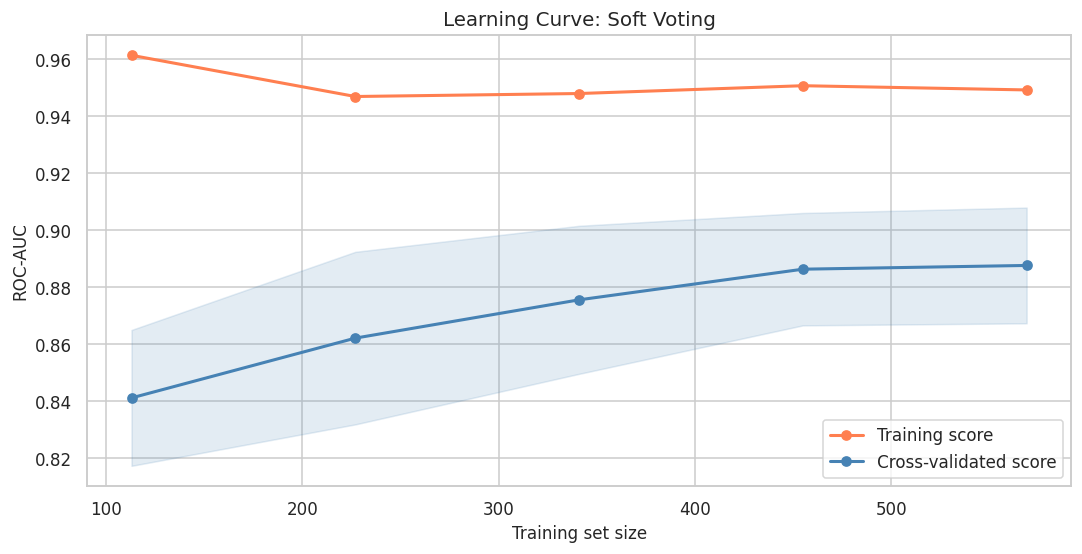

Final train-validation gap: 0.062   Gain from the last 20% of data: +0.0013
Large gap = variance (more data or stronger regularisation helps). Low, flat curves = bias (need better features or models).


In [ ]:
# ── 10.8  Learning curve: would more data help? ──────────────────────

sizes, tr_lc, va_lc = learning_curve(clone(final_model), X_train, y_train, cv=cv_fast, scoring="roc_auc",
                                     train_sizes=np.linspace(0.2, 1.0, 5), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(sizes, tr_lc.mean(axis=1), "o-", color="coral", linewidth=2, label="Training score")
ax.plot(sizes, va_lc.mean(axis=1), "o-", color="steelblue", linewidth=2, label="Cross-validated score")
ax.fill_between(sizes, va_lc.mean(axis=1) - va_lc.std(axis=1), va_lc.mean(axis=1) + va_lc.std(axis=1), color="steelblue", alpha=0.15)
ax.set_xlabel("Training set size"); ax.set_ylabel("ROC-AUC")
ax.set_title(f"Learning Curve: {final_name}")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

gap = tr_lc.mean(axis=1)[-1] - va_lc.mean(axis=1)[-1]
slope = va_lc.mean(axis=1)[-1] - va_lc.mean(axis=1)[-2]
print(f"Final train-validation gap: {gap:.3f}   Gain from the last 20% of data: {slope:+.4f}")
print("Large gap = variance (more data or stronger regularisation helps). Low, flat curves = bias (need better features or models).")

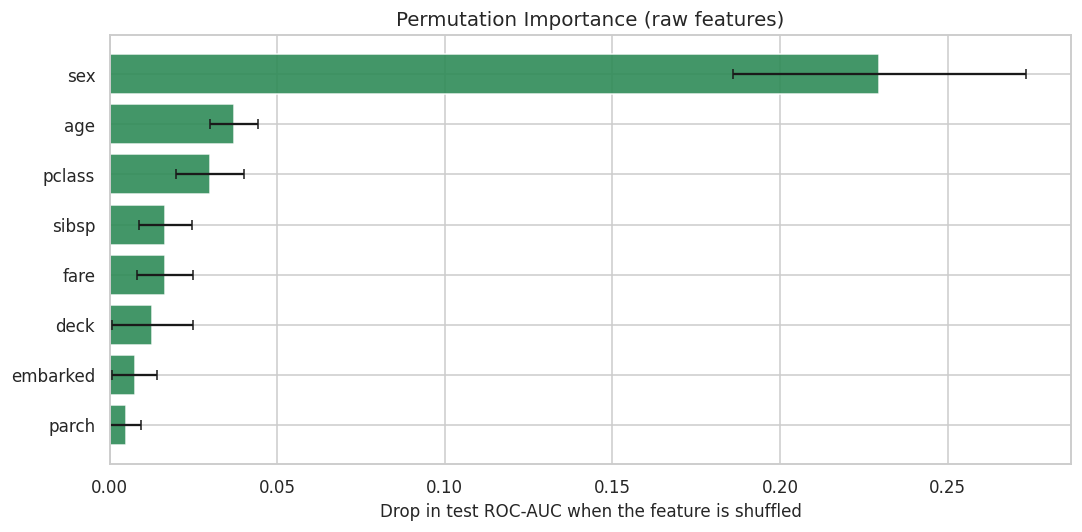

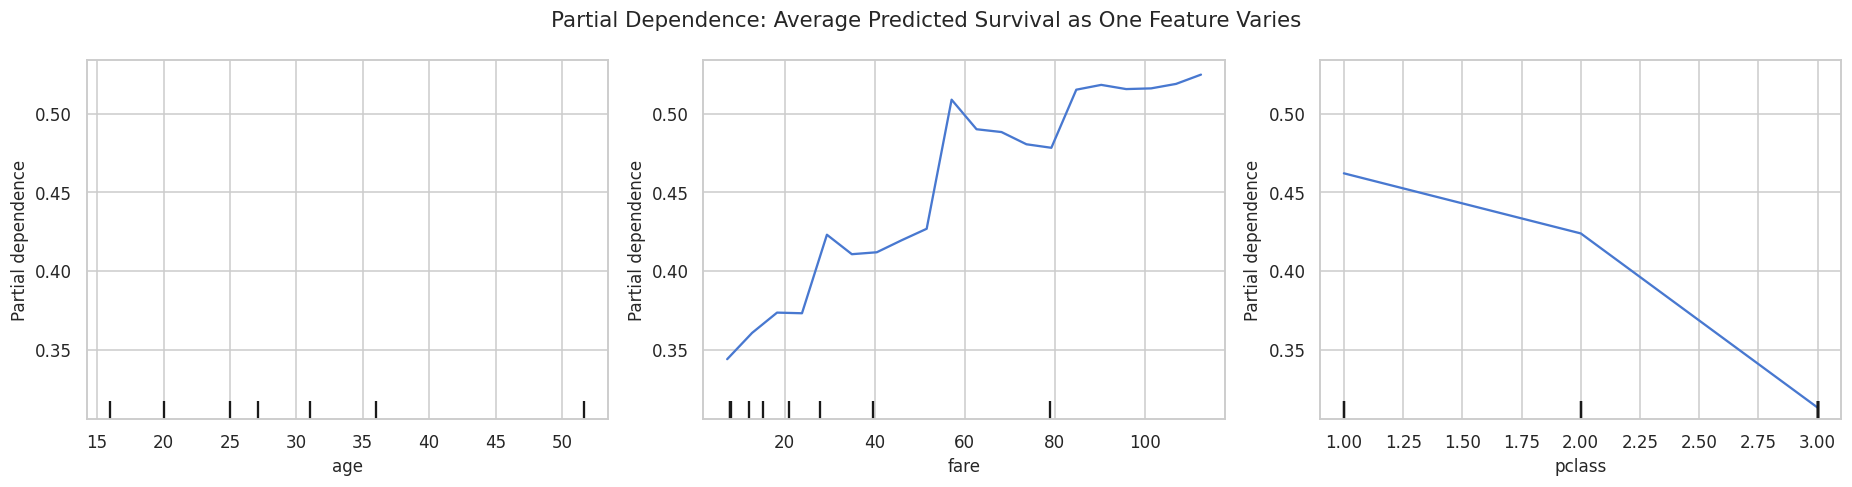

 feature  importance    std
     sex      0.2296 0.0437
     age      0.0371 0.0072
  pclass      0.0300 0.0101
   sibsp      0.0166 0.0079
    fare      0.0165 0.0083
    deck      0.0127 0.0121
embarked      0.0075 0.0067
   parch      0.0047 0.0046

Permutation importance is model-agnostic and measured on held-out data. Correlated features share credit,
so a low value can mean 'redundant', not 'useless'. Partial dependence shows the direction and shape of the effect.


In [ ]:
# ── 10.9  Interpretation: permutation importance and partial dependence ─
# We pass the RAW columns to the whole pipeline, so importances refer to the original features.

perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=15, random_state=RANDOM_STATE)
perm_df = pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std}
                       ).sort_values("importance")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(perm_df["feature"], perm_df["importance"], xerr=perm_df["std"], color="seagreen", edgecolor="white", alpha=0.9, capsize=3)
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled")
ax.set_title("Permutation Importance (raw features)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
PartialDependenceDisplay.from_estimator(final_model, X_test, ["age", "fare", "pclass"], grid_resolution=20,
                                        kind="average", ax=axes)
fig.suptitle("Partial Dependence: Average Predicted Survival as One Feature Varies", fontsize=14)
plt.tight_layout()
plt.show()

print(perm_df.sort_values("importance", ascending=False).round(4).to_string(index=False))
print("\nPermutation importance is model-agnostic and measured on held-out data. Correlated features share credit,")
print("so a low value can mean 'redundant', not 'useless'. Partial dependence shows the direction and shape of the effect.")

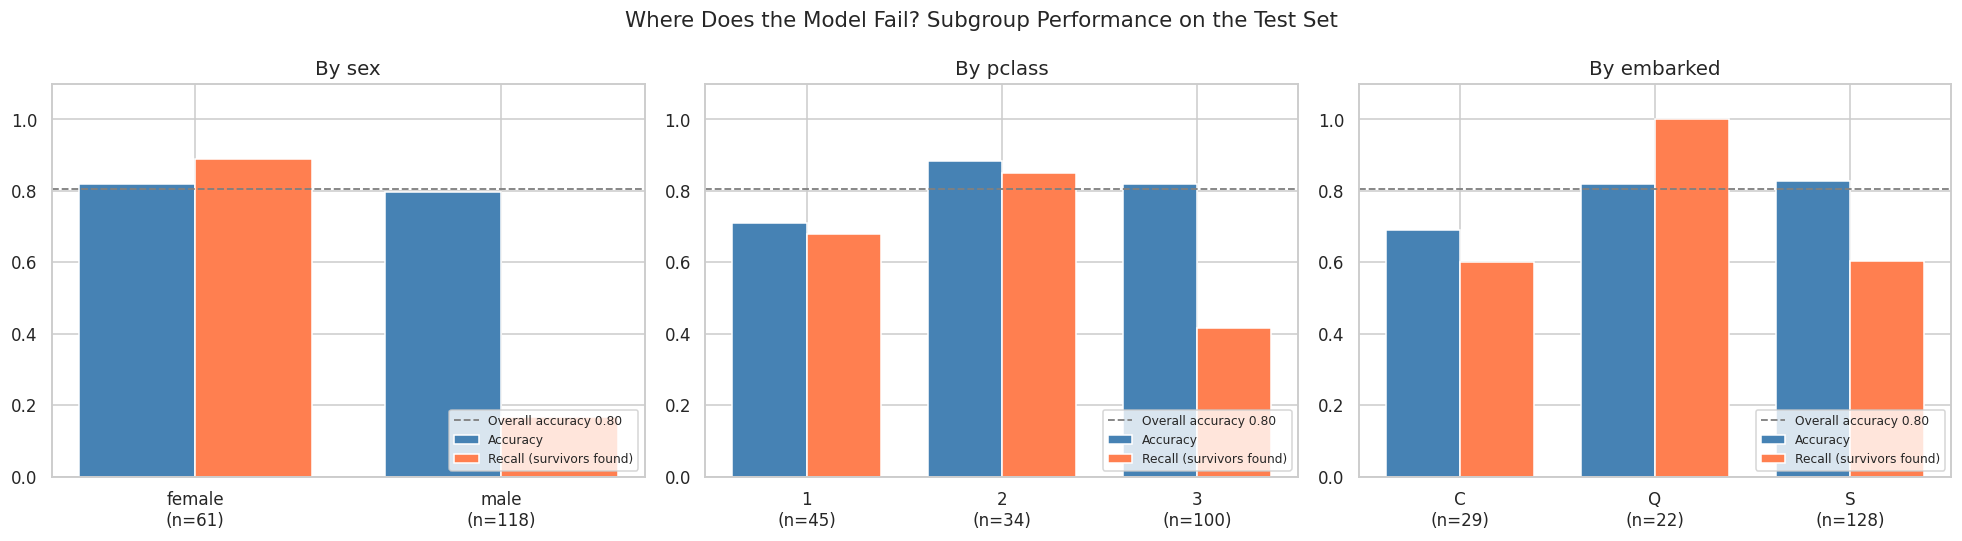

Most confidently wrong predictions (the cases to investigate by hand):
     pclass     sex   age    fare embarked deck  actual  p_survive
271       3    male  25.0    0.00        S  NaN       1       0.04
570       2    male  62.0   10.50        S  NaN       1       0.04
804       3    male  27.0    6.98        S  NaN       1       0.05
297       1  female   2.0  151.55        S    C       0       0.93
444       3    male   NaN    8.11        S  NaN       1       0.08
17        2    male   NaN   13.00        S  NaN       1       0.08
199       2  female  24.0   13.00        S  NaN       0       0.92
146       3    male  27.0    7.80        S  NaN       1       0.12

A good overall score can hide a weak subgroup. Always check performance across the groups that matter.


In [ ]:
# ── 10.10  Error analysis and subgroup performance ───────────────────

res_df = X_test.copy()
res_df["actual"] = y_test.values
res_df["p_survive"] = proba[final_name]
res_df["pred"] = pred_final
res_df["correct"] = res_df["pred"] == res_df["actual"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Where Does the Model Fail? Subgroup Performance on the Test Set", fontsize=14)
overall_acc = res_df["correct"].mean()
for ax, col in zip(axes, ["sex", "pclass", "embarked"]):
    g = res_df.groupby(col).agg(accuracy=("correct", "mean"), n=("correct", "size"),
                                recall=("pred", lambda s: recall_score(res_df.loc[s.index, "actual"], s, zero_division=0)))
    xx = np.arange(len(g)); w = 0.38
    ax.bar(xx - w / 2, g["accuracy"], w, color="steelblue", edgecolor="white", label="Accuracy")
    ax.bar(xx + w / 2, g["recall"],   w, color="coral", edgecolor="white", label="Recall (survivors found)")
    ax.set_xticks(xx); ax.set_xticklabels([f"{i}\n(n={n})" for i, n in zip(g.index, g["n"])])
    ax.axhline(overall_acc, color="grey", linestyle="--", linewidth=1.2, label=f"Overall accuracy {overall_acc:.2f}")
    ax.set_ylim(0, 1.1); ax.set_title(f"By {col}"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

wrong = res_df[~res_df["correct"]].assign(confidence=lambda d: (d["p_survive"] - d["actual"]).abs()).sort_values("confidence", ascending=False)
print("Most confidently wrong predictions (the cases to investigate by hand):")
print(wrong[["pclass", "sex", "age", "fare", "embarked", "deck", "actual", "p_survive"]].head(8).round(2).to_string())
print("\nA good overall score can hide a weak subgroup. Always check performance across the groups that matter.")

### Exercise 3: Tune, Evaluate, Audit (penguins)

Continue with the **penguins** pipeline (predict `sex`):

1. **Tune** your best model with `RandomizedSearchCV` (at least 15 trials, `roc_auc`). Report best parameters and compare with defaults. Run a **nested CV** estimate for one simpler model.
2. Select the final model by **CV on the training set**, write down the choice, then fit on the full training set.
3. Open the test set once. Produce a **metric table** (accuracy, balanced accuracy, precision, recall, F1, MCC, ROC-AUC, PR-AUC, log loss, Brier).
4. Plot the **confusion matrix**, **ROC and PR curves**, and a **calibration curve** (try isotonic calibration).
5. Choose a **threshold on out-of-fold training predictions** and test it. State your cost assumption.
6. Compute **bootstrap 95% confidence intervals** for accuracy and ROC-AUC, and a **McNemar test** against Logistic Regression.
7. Plot a **learning curve**, **permutation importance** on raw features, and **accuracy by `species`** (subgroup analysis). Is the model equally good for all three species?

```python
# Your code here
```

```
# Your answer here
```

---
## Part 11: Results Summary and Deployment

A model is finished when someone else can **use** it. A scikit-learn `Pipeline` bundles feature engineering, preprocessing, and the classifier into **one object**: raw rows in, predictions out, no preprocessing code to forget.

In [ ]:
# ── 11.1  Final results table ────────────────────────────────────────

summary = pd.DataFrame({
    "CV ROC-AUC (train)": pd.Series(cv_auc),
    "Test ROC-AUC":       test_df["roc_auc"],
    "Test accuracy":      test_df["accuracy"],
    "Test F1":            test_df["f1"],
    "Test MCC":           test_df["mcc"],
    "Test Brier":         test_df["brier"],
}).sort_values("CV ROC-AUC (train)", ascending=False)
print(summary.round(4).to_string())

lo_a, hi_a = np.percentile(boot["accuracy"], [2.5, 97.5])
lo_u, hi_u = np.percentile(boot["roc_auc"], [2.5, 97.5])
print(f"""
MODEL CARD
  Task:            predict Titanic survival from boarding information
  Final model:     {final_name}  (chosen by training-set CV before the test set was opened)
  Training data:   {len(X_train)} passengers      Test data: {len(X_test)} passengers
  Test accuracy:   {test_df.loc[final_name, 'accuracy']:.3f}  (95% CI {lo_a:.3f} to {hi_a:.3f})
  Test ROC-AUC:    {test_df.loc[final_name, 'roc_auc']:.3f}  (95% CI {lo_u:.3f} to {hi_u:.3f})
  Calibration:     Brier {test_df.loc[final_name, 'brier']:.3f}; check the reliability diagram (Part 10.5) before using probabilities directly
  Known weakness:  see subgroup and 'confidently wrong' analysis in Part 10.10
  Not suitable for: decisions about real people (small, historical, non-representative sample)""")

                       CV ROC-AUC (train)  Test ROC-AUC  Test accuracy  Test F1  Test MCC  Test Brier
Soft Voting                        0.8878        0.8439         0.8045   0.7154    0.5798      0.1400
Stacking                           0.8872        0.8437         0.7933   0.7040    0.5549      0.1397
Random Forest (tuned)              0.8817        0.8304         0.7654   0.6667    0.4935      0.1546
HistGB (tuned)                     0.8809        0.8381         0.8156   0.7442    0.6048      0.1486
Logistic Regression                0.8691        0.8506         0.8101   0.7167    0.5936      0.1394
CART (tuned)                       0.8665        0.8191         0.7598   0.6718    0.4849      0.1643

MODEL CARD
  Task:            predict Titanic survival from boarding information
  Final model:     Soft Voting  (chosen by training-set CV before the test set was opened)
  Training data:   712 passengers      Test data: 179 passengers
  Test accuracy:   0.804  (95% CI 0.743 to 0.860

In [ ]:
# ── 11.2  Save, reload, and score brand-new passengers ───────────────

joblib.dump(final_model, "titanic_survival_pipeline.joblib")
loaded = joblib.load("titanic_survival_pipeline.joblib")

new_passengers = pd.DataFrame([
    {"pclass": 1, "sex": "female", "age": 29.0,   "sibsp": 0, "parch": 1, "fare": 120.0, "embarked": "C", "deck": "B"},
    {"pclass": 3, "sex": "male",   "age": 22.0,   "sibsp": 0, "parch": 0, "fare": 7.9,   "embarked": "S", "deck": np.nan},
    {"pclass": 3, "sex": "female", "age": np.nan, "sibsp": 1, "parch": 2, "fare": 15.5,  "embarked": "Q", "deck": np.nan},   # missing age is fine
])[X.columns]

out = new_passengers.copy()
out["p_survive"] = loaded.predict_proba(new_passengers)[:, 1].round(3)
out["prediction"] = np.where(loaded.predict(new_passengers) == 1, "Survived", "Died")
print(out.to_string())

assert np.allclose(loaded.predict_proba(X_test)[:, 1], final_model.predict_proba(X_test)[:, 1])
print("\nReloaded pipeline reproduces the original predictions exactly.")
print("The pipeline handled a missing age, an unseen deck value, and raw strings with no extra code.")
print("To load it in another script, the TitanicFeatures class must be importable (put it in a .py module).")
import sklearn; print(f"Trained with scikit-learn {sklearn.__version__}: pin the version when deploying.")

   pclass     sex   age  sibsp  parch   fare embarked deck  p_survive prediction
0       1  female  29.0      0      1  120.0        C    B      0.990   Survived
1       3    male  22.0      0      0    7.9        S  NaN      0.081       Died
2       3  female   NaN      1      2   15.5        Q  NaN      0.589   Survived



Reloaded pipeline reproduces the original predictions exactly.
The pipeline handled a missing age, an unseen deck value, and raw strings with no extra code.
To load it in another script, the TitanicFeatures class must be importable (put it in a .py module).
Trained with scikit-learn 1.8.0: pin the version when deploying.


---
## Part 12: The Full-Pipeline Dashboard: Storytelling

**Storytelling checklist:**
1. **Comparison:** which models were tried and how did they rank under CV?
2. **Discrimination:** how well does the final model separate survivors from non-survivors?
3. **Errors:** what mistakes does it make?
4. **Drivers:** what is it relying on?

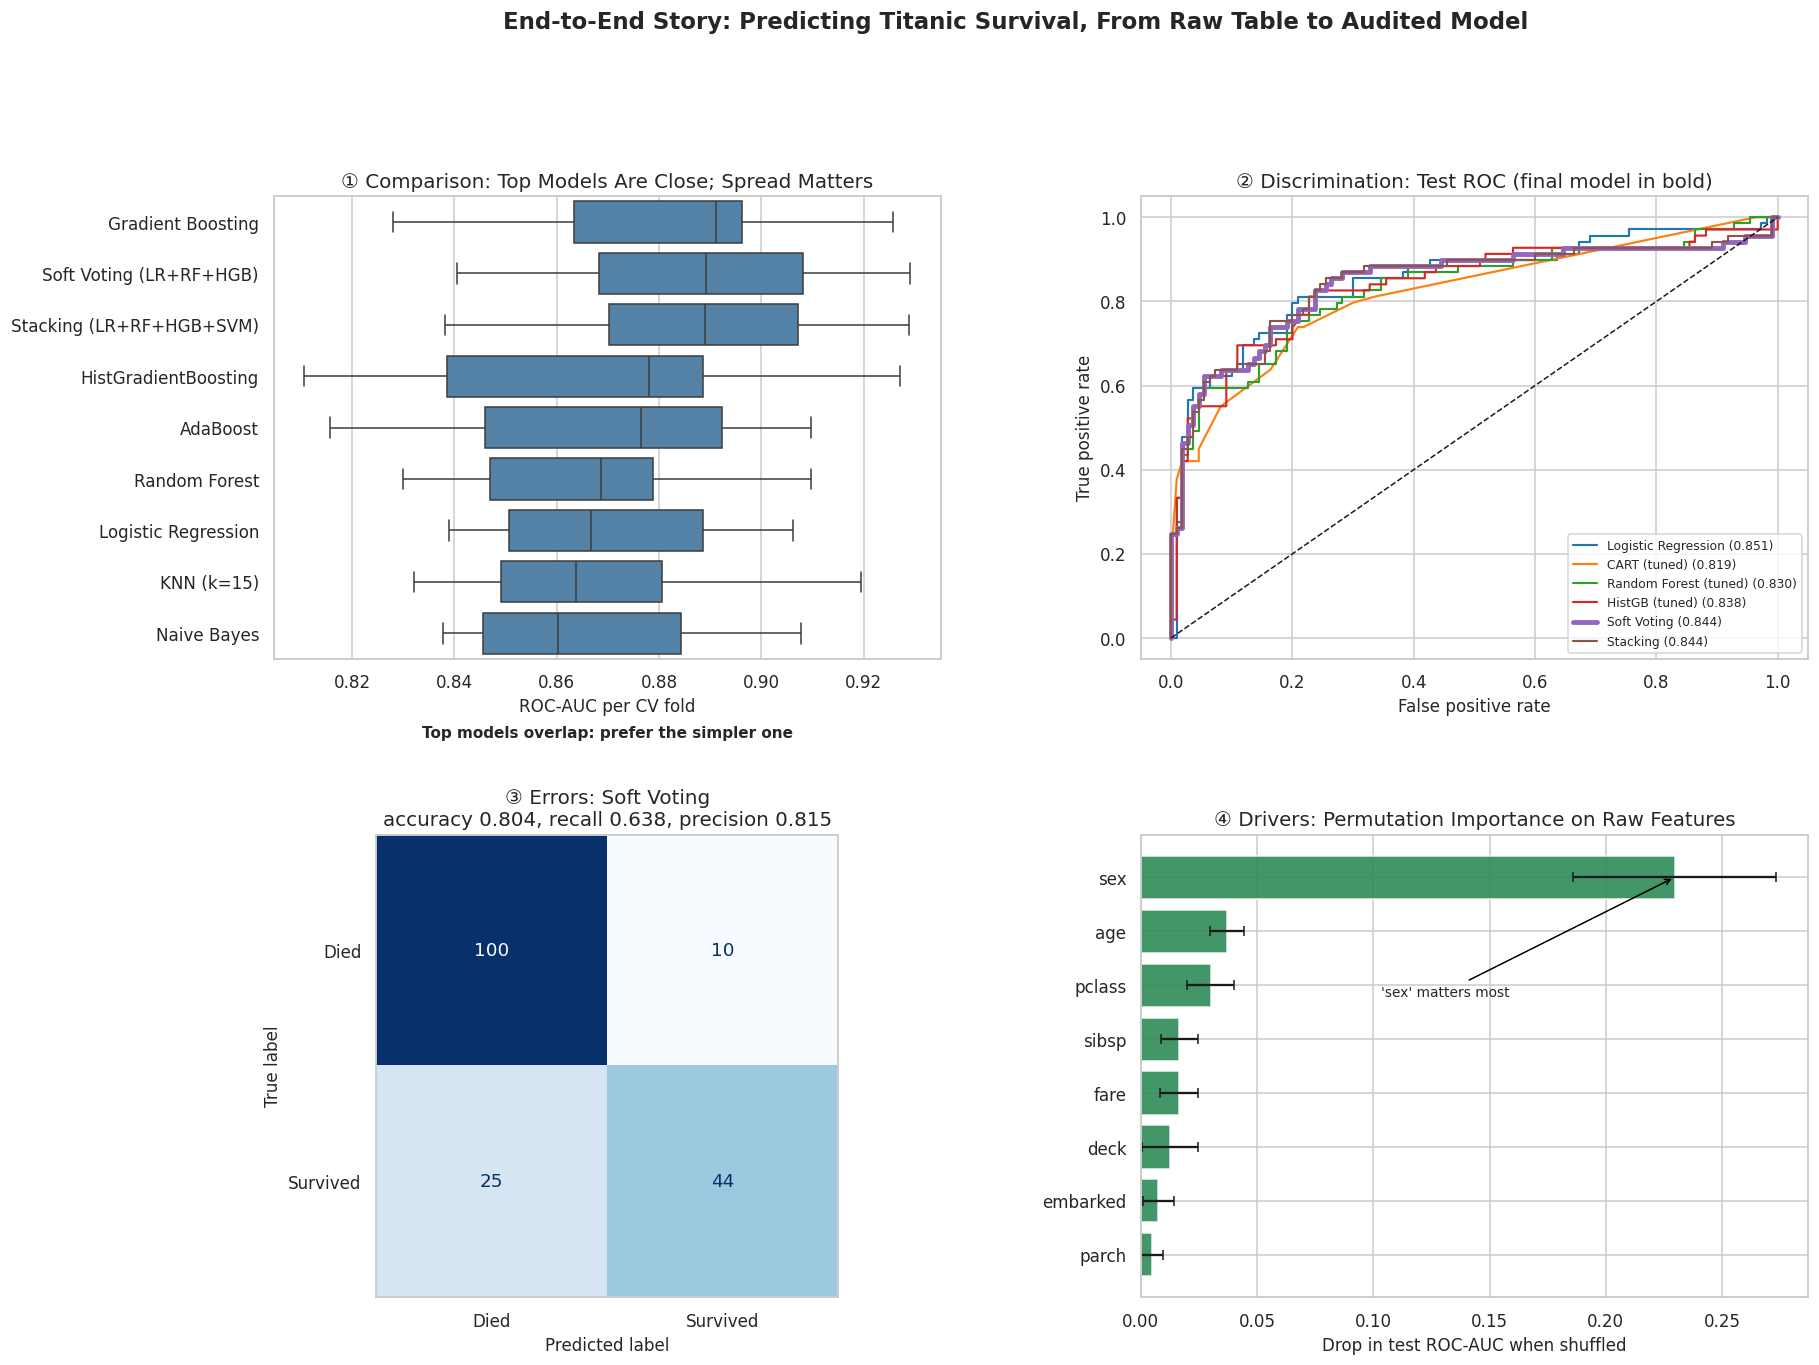

Dashboard saved as pipeline_dashboard.png


In [ ]:
# ── 12.1  The End-to-End Dashboard ───────────────────────────────────

fig = plt.figure(figsize=(18, 13))
fig.suptitle("End-to-End Story: Predicting Titanic Survival, From Raw Table to Audited Model",
             fontsize=15, fontweight="bold", y=1.01)
gs = gridspec.GridSpec(2, 2, hspace=0.38, wspace=0.30)

# ── Panel 1: CV comparison of the top models ──────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
top_models = pd.DataFrame(fold_auc).median().sort_values(ascending=False).head(9).index.tolist()
sns.boxplot(data=pd.DataFrame(fold_auc)[top_models], orient="h", color="steelblue", ax=ax1)
ax1.set_xlabel("ROC-AUC per CV fold")
ax1.set_title("① Comparison: Top Models Are Close; Spread Matters")
ax1.text(0.5, -0.17, "Top models overlap: prefer the simpler one", transform=ax1.transAxes, ha="center",
         fontsize=10, fontweight="bold")

# ── Panel 2: ROC curves ───────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
for (name, p), color in zip(proba.items(), palette):
    fpr, tpr, _ = roc_curve(y_test, p)
    ax2.plot(fpr, tpr, color=color, linewidth=3.2 if name == final_name else 1.4,
             label=f"{name} ({roc_auc_score(y_test, p):.3f})")
ax2.plot([0, 1], [0, 1], "k--", linewidth=1)
ax2.set_xlabel("False positive rate"); ax2.set_ylabel("True positive rate")
ax2.set_title("② Discrimination: Test ROC (final model in bold)")
ax2.legend(loc="lower right", fontsize=8)

# ── Panel 3: confusion matrix ─────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, display_labels=["Died", "Survived"], cmap="Blues",
                                        colorbar=False, ax=ax3, values_format="d")
ax3.grid(False)
m_final = test_df.loc[final_name]
ax3.set_title(f"③ Errors: {final_name}\naccuracy {m_final['accuracy']:.3f}, recall {m_final['recall']:.3f}, precision {m_final['precision']:.3f}")

# ── Panel 4: drivers ──────────────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
ax4.barh(perm_df["feature"], perm_df["importance"], xerr=perm_df["std"], color="seagreen", edgecolor="white", alpha=0.9, capsize=3)
ax4.set_xlabel("Drop in test ROC-AUC when shuffled")
ax4.set_title("④ Drivers: Permutation Importance on Raw Features")
lead = perm_df.iloc[-1]
ax4.annotate(f"'{lead['feature']}' matters most", xy=(lead["importance"], len(perm_df) - 1),
             xytext=(lead["importance"] * 0.45, len(perm_df) - 3.2), fontsize=9,
             arrowprops=dict(arrowstyle="->", color="black"))

plt.tight_layout()
plt.savefig("pipeline_dashboard.png", dpi=110, bbox_inches="tight")
plt.show()
print("Dashboard saved as pipeline_dashboard.png")

### Exercise 4: Final Challenge: The Complete Pipeline Report (penguins)

Deliver a **complete, reproducible project** on the **penguins** dataset (predict `sex`). Your notebook section must contain, in order:

1. **Audit and EDA** with at least one statistical test.
2. **Sealed split** and a stated CV scheme.
3. **One `Pipeline`** containing: custom feature engineering, a `ColumnTransformer` (imputation, scaling, encoding), optional feature selection, and a classifier.
4. **Model comparison** of at least 8 models with repeated CV, including CART, Random Forest, a boosting model, Voting, and Stacking, plus a significance test.
5. **Tuning** with random search and one nested-CV estimate.
6. **Final evaluation** on the test set: full metric table, confusion matrix, ROC/PR, calibration, threshold, bootstrap CIs, subgroup analysis by species, permutation importance.
7. A **2×2 `GridSpec` dashboard** (comparison, ROC, confusion matrix, drivers) with at least one annotation.
8. **Save** the pipeline with `joblib`, reload it, and score two new penguins you invent, including one with a missing value.
9. A short **model card** (task, data, final model, test metrics with confidence intervals, known weaknesses, unsuitable uses).
10. Write 4-5 sentences answering:
   - Which preprocessing and engineering choices mattered most, and how do you know?
   - Did any ensemble beat the best single model significantly?
   - How confident are you in the final test numbers, and why?
   - Where does the model fail, and what would you do next?

```python
# Your code here
```

```
# Your answer here
```

---
## Summary

| Stage | What it solves | Key tools |
|---|---|---|
| **Audit** | Types, missingness, balance, leakage | `isna`, `crosstab`, equality checks |
| **EDA + tests** | Patterns and whether they are real | chi-square, Mann-Whitney U, effect sizes |
| **Sealed split** | An honest final test | `train_test_split(stratify=y)` |
| **Validation scheme** | Stable model comparison | `RepeatedStratifiedKFold`, nested CV, bootstrap |
| **Imputation** | Missing values | `SimpleImputer`, `KNNImputer`, `IterativeImputer`, indicator flags |
| **Outliers and skew** | Extreme values | `log1p`, `PowerTransformer`, `QuantileTransformer`, `RobustScaler` |
| **Encoding** | Categories to numbers | `OneHotEncoder(handle_unknown="ignore")` |
| **Scaling** | Distance and gradient models | `StandardScaler`, `MinMaxScaler`, `RobustScaler` |
| **Feature engineering** | Expose structure | custom `TransformerMixin`, ratios, flags, interactions |
| **Feature selection** | Remove noise | `SelectKBest`, `RFE`, `SelectFromModel`, `PCA` |
| **Models** | Different inductive biases | Logistic, KNN, NB, SVM, **CART**, forests, boosting |
| **Ensembles** | Cancel errors | Bagging, boosting, **Voting**, **Stacking** |
| **Tuning** | Hyperparameters without fooling yourself | `GridSearchCV`, `RandomizedSearchCV`, nested CV |
| **Evaluation** | Honest, multi-angle judgement | accuracy to MCC, ROC/PR, calibration, thresholds, CIs, McNemar |
| **Diagnosis** | Bias vs variance | learning and validation curves |
| **Interpretation and audit** | Trust and fairness | permutation importance, partial dependence, subgroup errors |
| **Deployment** | Reuse | one `Pipeline`, `joblib` |

---
**The end-to-end decision loop:**
1. Audit for missingness, imbalance, **leakage and redundancy**  
2. Seal the test set before learning anything  
3. Put **every** learned step inside one `Pipeline`  
4. Compare models and ensembles with repeated CV and a significance test; prefer the simpler model when tied  
5. Tune with random search; estimate the tuned score with nested CV  
6. Open the test set **once**, report several metrics with confidence intervals  
7. Check calibration, choose the threshold on training data with an explicit cost, inspect subgroups and confident errors  
8. Save the whole pipeline, document its limits, and monitor it after deployment